# 반도체 웨이퍼 결함 데이터로 배우는 머신러닝 A to Z
**바이브코딩(Vibe Coding) 실습판 — 회귀 · 분류 · 평가지표 · 변수 중요도**

| 항목 | 내용 |
|---|---|
| **과정** | 스마트제조 데이터의 이해 — 머신러닝 편 |
| **데이터** | `반도체_웨이퍼_basic_raw_data.csv` (63,908행 × 25열, 결함 1개 = 1행) |
| **선수 학습** | `반도체_웨이퍼_EDA_기초통계_A_to_Z.ipynb` (EDA는 앞 노트북에서 완료) |
| **도구** | Python · pandas · scikit-learn · matplotlib · seaborn + **생성형 AI** |
| **분류 과제** | 검사 장비가 잡은 결함이 **진성결함(REAL)인지 가성결함(FALSE)인지** 판정 |
| **회귀 과제** | 크기 측정값 없이 **신호·형상·위치·공정 정보로 결함 크기(SIZE_D, µm)를 추정** |


## 학습 안내

**규칙을 외우는 수업에서, 모델이 규칙을 배우는 과정을 이해하는 수업으로**

3일차에서 배운 데이터 구조·EDA를 바탕으로 **알고리즘의 예측식, 학습 목적, 학습 과정, 주요 설정값, 장단점**을 자세히 살펴봅니다.
원본의 분류·회귀·그룹 검증·튜닝·모델 해석 실습을 유지하면서 손계산 예제와 학습 과정 시각화를 추가했습니다.
교육용 가상 데이터와 실제 웨이퍼 분석은 각 셀에 구분해 표시합니다. 표와 그래프는 실제 실행 결과입니다.

| 학습 순서 | 배울 질문 | 확인할 실습 |
|---|---|---|
| 알고리즘 공통 원리 | 무엇을 줄이면서 배우는가? | 손실함수·경사하강법 |
| 선형 회귀·릿지 | 직선을 어떻게 찾고 계수를 어떻게 억제하는가? | 예측식·잔차·정규화 |
| 로지스틱 회귀 | 숫자 점수를 어떻게 확률로 바꾸는가? | 시그모이드·로그손실·임계값 |
| 의사결정나무 | 어떤 질문으로 데이터를 나누는가? | 지니 불순도 손계산·나무 그림 |
| 랜덤포레스트 | 다른 나무를 모으면 무엇이 달라지는가? | 복원추출·나무별 예측 평균 |
| 부스팅·HGB | 앞 모델의 부족한 부분을 어떻게 보완하는가? | 잔차를 학습하는 작은 나무·학습률 |
| 실제 데이터 비교 | 새 로트에도 잘 맞는가? | Pipeline·그룹 교차검증·튜닝 |
| 의사결정과 해석 | 성능을 현장 행동과 어떻게 연결하는가? | 임계값·오류 분석·중요도·PDP |

**실행**: 커널을 다시 시작한 뒤 위에서 아래로 실행하세요. CSV는 현재 폴더 또는 상위 폴더에서 찾습니다.
기본 `QUICK=True`는 **전체 데이터**를 사용하되 3겹 CV, 4개 튜닝 후보 등으로 반복 계산을 줄인 교육 설정입니다.
`QUICK=False`는 5겹 CV와 더 넓은 탐색을 수행하므로 시간이 늘어납니다. 결과는 설정·버전에 따라 달라집니다.
원본의 고정 성능 숫자를 재사용하지 않고 아래 실제 계산값으로 해석합니다.

**이번 확장본에서 보완한 검증**: 음수 R² 유지, 원인 미확인 키 중복 보존, 로트 분리,
그룹 검증과 맞지 않는 HGB 내부 무작위 조기종료 비활성화, 학습 데이터에서 임계값 선결정,
변수 선택은 각 CV 학습 폴드 내부에서 수행합니다. 테스트 결과를 본 뒤 모델을 바꾸면 별도 최종 검증이 필요합니다.


## 이 노트북을 읽는 방법

**개념 → 프롬프트 → 코드 실행 → 표·그래프 읽기 → 결과 해석** 순서로 살펴보세요.

| 구분 | 학습할 내용 |
|---|---|
| **알고리즘 상세 해설** | 예측식·손실·학습 과정·설정값을 작은 예제와 함께 이해합니다. |
| **실습 프롬프트** | AI에 요청할 작업과 검증 조건을 확인하고 아래 코드와 비교합니다. |
| **실행 결과와 그래프 읽기** | 바로 앞 예제의 출력에서 확인할 사항과 해석의 한계를 읽습니다. |
| **이번 실행 결과 해석** | 실제 웨이퍼 실습의 계산값을 분모·단위·검증 방식과 함께 확인합니다. |

> **실행 순서**  
> 코드 셀은 앞에서 생성한 변수와 모델을 사용합니다. 처음 실행할 때는 **0장부터 위에서 아래로** 실행하세요. 목차 링크는 읽을 위치를 이동하는 용도입니다.

**학습 흐름** · 원리 이해(1장) → 데이터와 검증 설계(2–4장) → 분류·회귀 실습(5–6장) → 모델 해석과 정리(7–8장)


<a id="contents"></a>

## 목차


| 장 | 주제 | 핵심 키워드 |
|:---:|---|---|
| [**가이드**](#guide) | 바이브코딩 가이드 (ML 편) | ML 프롬프트 구조, 세션 시작 프롬프트 |
| [**0**](#chapter-0) | 실습 환경 준비 | scikit-learn, 공통 설정 |
| [**1**](#chapter-1) | 머신러닝 개념 | 지도학습, 회귀 vs 분류, 과적합, 데이터 누수 |
| [**2**](#chapter-2) | 문제 정의 & 데이터 준비 | 타깃·특성 선정, 누수 변수 제거 |
| [**3**](#chapter-3) | 데이터 분할 & 전처리 파이프라인 | 학습/테스트, 교차검증, 그룹 분할, Pipeline |
| [**4**](#chapter-4) | 평가지표 선택 | 혼동행렬, 정밀도·재현율·F1·AUC, MAE·RMSE·R² |
| [**5**](#chapter-5) | 분류 모델링 | 기준 모델 → 로지스틱 → 트리 → 앙상블, 튜닝, 임계값 |
| [**6**](#chapter-6) | 회귀 모델링 | 로그 변환 타깃, 모델 비교, 잔차 분석 |
| [**7**](#chapter-7) | 변수 중요도 | 계수, 불순도 중요도, 순열 중요도, 그룹 중요도, PDP |
| [**8**](#chapter-8) | 모델 저장 · 종합 리포트 · 연습문제 | 프롬프트 작성 실습 |
| **복습** | [알고리즘 복습·실습 문제](#review) | 실행 과제, 보고서 틀, 참고 문서 |

```
 문제 정의 → 데이터 준비 → 분할 → 전처리 → 기준 모델 → 모델 비교(교차검증) → 튜닝
     → 임계값 결정(학습 데이터) → 테스트 평가 → 오차 분석 → 변수 중요도 → 저장·보고
```


---

<a id="guide"></a>

## 바이브코딩 가이드 — 머신러닝 편

이 노트북의 **모든 코드 셀 위에는 `프롬프트 Pxx`** 가 있습니다.

```
 ① 프롬프트 읽기  →  ② AI에게 복사·붙여넣기  →  ③ 생성된 코드 실행
        ▲                                              │
        │                                              ▼
 ⑥ 프롬프트 수정  ◀──  ⑤ 차이점 분석  ◀──  ④ 노트북의 '예시 코드'와 비교
```

[전체 목차](#contents) · [다음 장](#chapter-0)

**이 장의 개념과 실습**

- [머신러닝 프롬프트의 5요소 — 맥락 · 작업 · **검증 방법** · 조건 · 출력](#guide-topic-5)
- [AI가 만든 머신러닝 코드 검증 체크리스트](#guide-topic-6)
- [세션 시작 프롬프트 (가장 먼저 AI에게 입력하세요)](#guide-topic-7)


<a id="guide-topic-5"></a>

### 머신러닝 프롬프트의 5요소 — 맥락 · 작업 · **검증 방법** · 조건 · 출력

EDA 프롬프트(맥락·작업·조건·출력)에 **검증 방법**이 하나 더 붙습니다. 머신러닝은 "어떻게 평가하느냐"를 빼면 AI가 **누수가 있는 코드**를 만들기 쉽기 때문입니다.

| 요소 | 설명 | 예시 |
|---|---|---|
| **맥락** | 변수 이름·현재 상태 | "`Xc_tr`, `yc_tr`에 학습용 분류 데이터가 있어. 1=REAL이야." |
| **작업** | 무엇을 할지 | "로지스틱 회귀와 랜덤포레스트를 비교해줘." |
| **검증 방법** | 분할·교차검증·지표 | "`GroupKFold(5)`로 `g_tr`(로트) 기준 교차검증, 지표는 ROC-AUC." |
| **조건** | 라이브러리·제약 | "scikit-learn `Pipeline`으로 전처리를 포함하고 `random_state=42`." |
| **출력** | 결과 형태 | "모델별 평균±표준편차 표, 소수점 3자리, 한글 주석." |

> **나쁜 예** : "랜덤포레스트로 분류해줘"
> **좋은 예** : "`Xc_tr`/`yc_tr`로 랜덤포레스트 분류기를 `Pipeline`(전처리 `make_prep`)으로 만들고, `g_tr` 기준 `GroupKFold(5)` 교차검증으로 ROC-AUC 평균과 표준편차를 출력해줘. 테스트 데이터는 쓰지 마."


<a id="guide-topic-6"></a>

### AI가 만든 머신러닝 코드 검증 체크리스트

- [ ] **테스트 데이터를 학습·튜닝·임계값 결정에 쓰지 않았는가?** (가장 흔한 실수)
- [ ] **스케일러·인코더를 전체 데이터로 `fit` 하지 않았는가?** → `Pipeline` 안에 넣었는지 확인
- [ ] **타깃을 그대로 담은 변수(누수 변수)가 특성에 들어가지 않았는가?** (예: `Class`)
- [ ] **같은 로트가 학습·테스트에 동시에 들어가지 않았는가?** (그룹 분할)
- [ ] **기준 모델(Dummy)보다 얼마나 좋은지 비교했는가?**
- [ ] **지표가 문제의 목적과 맞는가?** (정확도만 보고 있지 않은가?)
- [ ] **`random_state`를 고정해 결과가 재현되는가?**


<a id="guide-topic-7"></a>

### 세션 시작 프롬프트 (가장 먼저 AI에게 입력하세요)

```text
너는 제조 데이터 머신러닝을 가르치는 Python 튜터야.
Jupyter Notebook에서 pandas, numpy, scikit-learn, matplotlib, seaborn으로 실습할 거야.
EDA는 이미 끝났고, 이번에는 모델링에 집중해.

[데이터] 반도체_웨이퍼_basic_raw_data.csv (UTF-8 BOM, 63,908행 × 25열, 결함 1개 = 1행)
- 식별: Step, Step_desc(공정: PC, RMG, CBCMP), Lot Name(로트), Slot No, Defect No
- 분류 결과: Class(결함 분류 코드, 9=가성결함), IS_DEFECT('REAL'/'FALSE')
- 크기: SIZE_X, SIZE_Y, SIZE_D(µm), DEFECT_AREA(µm²)
- 신호: INTENSITY, POLARITY(-1/0/1), ENERGY_PARAM, MDAT_OFFSET, MDAT_GL, MDAT_NOISE,
        RELATIVEMAGNITUDE, PATCHDEFECTSIGNAL
- 형상: ALIGNRATIO, SPOTLIKENESS, PATCHNOISE, ACTIVERATIO
- 위치: RADIUS(µm), ANGLE(도)

[과제]
- 분류: IS_DEFECT 예측 (REAL=1, FALSE=0). Class는 타깃을 그대로 담고 있으므로 특성에서 제외.
- 회귀: log10(SIZE_D) 예측. SIZE_X, SIZE_Y, DEFECT_AREA는 크기 자체라 특성에서 제외.

[규칙]
- 데이터프레임은 df, 난수 시드는 RANDOM_STATE = 42.
- 같은 로트(Lot Name)가 학습/테스트에 섞이지 않도록 그룹 기준으로 분할·교차검증해.
- 전처리는 반드시 scikit-learn Pipeline/ColumnTransformer 안에서 해.
- 테스트 데이터는 최종 평가에만 한 번 사용해.
- 코드 각 줄에 한글 주석, 그래프 제목·축은 한글(Malgun Gothic).
- 코드 아래에 결과 해석 방법을 2~3줄로 설명해줘.
```


---

<a id="chapter-0"></a>

## 0장. 실습 환경 준비

> **이 장의 목표**
> - 머신러닝 실습에 필요한 라이브러리와 공통 설정을 준비한다.

[전체 목차](#contents) · [이전 장](#guide) · [다음 장](#chapter-1)


**실습 프롬프트 P01**

> 머신러닝 실습용 Jupyter 노트북 첫 셀을 작성해줘.
>
> **[작업]**
> 1. numpy, pandas, matplotlib.pyplot, seaborn을 관례적인 별칭으로 import하고 경고는 숨겨줘.
> 2. scikit-learn에서 앞으로 쓸 것들을 한 번에 import해줘:
>
>    - 분할/검증: GroupShuffleSplit, GroupKFold, KFold, cross_validate, cross_val_predict,
>
>                RandomizedSearchCV, validation_curve, learning_curve
>
>    - 전처리: ColumnTransformer, Pipeline, StandardScaler, OneHotEncoder
>
>    - 모델: DummyClassifier, DummyRegressor, LogisticRegression, LinearRegression, Ridge,
>
>            DecisionTreeClassifier/Regressor, RandomForestClassifier/Regressor,
>
>            HistGradientBoostingClassifier/Regressor
>
>    - 지표: 분류(accuracy, precision, recall, f1, roc_auc, average_precision, confusion_matrix,
>
>            roc_curve, precision_recall_curve), 회귀(mean_absolute_error, root_mean_squared_error,
>
>            r2_score), make_scorer
>
>    - 해석: permutation_importance, PartialDependenceDisplay
> 3. Windows/macOS/Linux를 판별해 한글 폰트를 설정하고 마이너스 기호 깨짐을 막아줘.
> 4. pandas 실수 출력은 소수점 4자리, seaborn whitegrid 테마.
> 5. 상수: RANDOM_STATE = 42, 색상 C_REAL="#eb6834", C_FALSE="#2a78d6",
>
>    공정 팔레트 PAL_STEP = PC 파랑 / RMG 주황 / CBCMP 초록("#1baf7a"), STEP_ORDER 리스트.
> 6. 로그 축 눈금을 0.1, 1, 10처럼 표시하는 plain_log(ax, axis) 함수.
> 7. 마지막에 pandas, numpy, scikit-learn 버전을 출력해줘.


pandas       : 3.1.0
numpy        : 2.5.3
scikit-learn : 1.9.1
교육 실행 설정: {'QUICK': True, 'CV': 3, '탐색 후보': 4, 'RF 나무': 60}


---

<a id="chapter-1"></a>

## 1장. 머신러닝 개념

> **이 장의 목표**
> - 지도학습의 회귀와 분류를 구분할 수 있다.
> - 과적합·일반화·데이터 누수의 의미를 설명할 수 있다.

[전체 목차](#contents) · [이전 장](#chapter-0) · [다음 장](#chapter-2)

**이 장의 개념과 실습**

- [1-1. 머신러닝이란?](#chapter-1-topic-12)
- [1-2. 핵심 용어](#chapter-1-topic-13)
- [1-3. 과적합과 과소적합](#chapter-1-topic-14)
- [1-4. 이번 실습에서 쓰는 모델](#chapter-1-topic-15)

**알고리즘 상세 해설 바로가기**

- [모델·알고리즘·손실함수는 어떻게 다른가?](#chapter-1-topic-16)
- [선형 회귀 — 오차 제곱합이 가장 작은 직선](#chapter-1-topic-19)
- [경사하강법 — 손실이 줄어드는 방향으로 조금씩 이동](#chapter-1-topic-22)
- [릿지 회귀 — 큰 계수에 비용을 부과하기](#chapter-1-topic-25)
- [로지스틱 회귀 — 직선 점수를 확률로 바꾸기](#chapter-1-topic-28)
- [의사결정나무 — 불순도가 줄어드는 질문 찾기](#chapter-1-topic-31)
- [랜덤포레스트 — 서로 다른 나무의 예측을 평균내기](#chapter-1-topic-34)
- [그래디언트 부스팅 — 부족한 예측을 순서대로 보완](#chapter-1-topic-37)
- [HistGradientBoosting — 값들을 구간으로 모아 빠르게 탐색](#chapter-1-topic-40)


<a id="chapter-1-topic-12"></a>

### 1-1. 머신러닝이란?

> **데이터에서 입력(X)과 정답(y) 사이의 규칙을 컴퓨터가 스스로 찾게 하고, 그 규칙으로 새 데이터의 정답을 예측하는 것**

```
   전통적 프로그래밍 :  규칙(사람이 작성) + 데이터  ──▶  답
   머신러닝          :  데이터 + 답(정답)          ──▶  규칙(모델)  ──▶ 새 데이터의 답
```

| 구분 | 정답(y) | 대표 과제 | 이 노트북 |
|---|---|---|---|
| **지도학습 – 분류** | 범주 (REAL / FALSE) | 불량 판정, 스팸 분류 | O 진성/가성결함 판정 |
| **지도학습 – 회귀** | 연속 숫자 | 수율·두께·크기 예측 | O 결함 크기(µm) 추정 |
| 비지도학습 | 없음 | 군집, 이상탐지 | (이번 범위 아님) |


<a id="chapter-1-topic-13"></a>

### 1-2. 핵심 용어

| 용어 | 뜻 | 이 데이터에서 |
|---|---|---|
| **특성 (Feature, X)** | 모델 입력 변수 | INTENSITY, SPOTLIKENESS, RADIUS … |
| **타깃 (Target, y)** | 맞히려는 값 | IS_DEFECT / log10(SIZE_D) |
| **학습 (fit)** | 데이터로 규칙을 찾는 과정 | `model.fit(X_train, y_train)` |
| **예측 (predict)** | 찾은 규칙을 새 데이터에 적용 | `model.predict(X_test)` |
| **하이퍼파라미터** | 사람이 정하는 모델 설정값 | 트리 깊이, 학습률 |
| **기준 모델 (Baseline)** | 아무 규칙 없이 예측하는 모델 | "모두 REAL", "모두 평균값" |
| **일반화 (Generalization)** | 처음 보는 데이터에서도 잘 맞는 성질 | 새 로트에서의 성능 |
| **과적합 (Overfitting)** | 학습 데이터는 외웠지만 새 데이터는 못 맞힘 | 학습 AUC 1.0, 테스트 0.8 |
| **데이터 누수 (Leakage)** | 예측 시점에 알 수 없는 정보가 학습에 섞임 | `Class`로 IS_DEFECT 예측 |


<a id="chapter-1-topic-14"></a>

### 1-3. 과적합과 과소적합

```
  오차 ▲
       │ \                                 ── 학습 오차
       │  \        ___..--- 검증 오차       ── 검증 오차
       │   \__..--'
       │    `--..__
       │           ``--..____ 학습 오차
       └──────────────────────────────▶ 모델 복잡도 (예: 트리 깊이)
         과소적합   │  적정  │   과적합
```
- **과소적합** : 모델이 너무 단순해 학습 데이터도 못 맞힘 → 복잡도↑, 특성 추가
- **과적합** : 학습 데이터의 잡음까지 외움 → 복잡도↓, 규제, 데이터 추가
- 둘 사이의 균형점을 **검증 데이터(교차검증)** 로 찾습니다. → 5장에서 직접 그려봅니다.


<a id="chapter-1-topic-15"></a>

### 1-4. 이번 실습에서 쓰는 모델

| 모델 | 원리 (한 줄) | 장점 | 단점 |
|---|---|---|---|
| **Dummy** | 최빈값/평균으로만 예측 | 비교 기준 | 예측력 없음 |
| **로지스틱 / 선형 회귀** | 특성의 가중합 | 해석 쉬움(계수) | 곡선·상호작용 못 잡음 |
| **의사결정나무** | 예/아니오 질문을 반복해 분할 | 직관적 | 과적합 쉬움 |
| **랜덤포레스트** | 나무 수백 개의 다수결/평균 | 안정적, 튜닝 쉬움 | 느리고 무거움 |
| **그래디언트 부스팅 (HGB)** | 앞 나무의 오차를 다음 나무가 보완 | 정형 데이터 최강급, 빠름 | 하이퍼파라미터 많음 |


<a id="chapter-1-topic-16"></a>

### 알고리즘 상세 해설 · 모델·알고리즘·손실함수는 어떻게 다른가?

**목표**: `fit()` 한 줄 안에서 무엇을 찾는지 설명합니다.

- **모델**은 입력을 예측으로 바꾸는 규칙입니다. 예: $\hat y=wx+b$.
- **파라미터**는 데이터로 찾는 수치입니다. 위 식의 $w,b$가 해당합니다.
- **손실함수**는 예측의 나쁨을 숫자로 나타냅니다. 회귀 MSE는 $\frac1n\sum(y_i-\hat y_i)^2$입니다.
- **학습 알고리즘**은 손실을 줄이는 파라미터를 찾는 절차입니다. 모든 모델이 경사하강법을 쓰는 것은 아닙니다.
- **하이퍼파라미터**는 학습 전에 정하는 설정입니다. 트리 깊이·릿지 alpha·학습률 등이 해당합니다.

학습 손실과 평가 지표는 같지 않을 수 있습니다. 아래에서는 제곱오차를 줄이지만, 실제 업무에서는 µm 단위 MAE가 더 이해하기 쉬울 수 있습니다.
손실이 작아져도 학습 자료를 외운 결과일 수 있으므로 별도 검증이 필요합니다.


,기울기 w,절편 b,예측값,MSE
0,0,0,"[0.0, 0.0, 0.0]",27.6667
1,1,0,"[1.0, 2.0, 3.0]",9.6667
2,2,0,"[2.0, 4.0, 6.0]",1.0000
3,2,1,"[3.0, 5.0, 7.0]",0.0000


**실행 결과와 그래프 읽기**

마지막 w=2, b=1에서는 세 정답을 정확히 맞혀 MSE가 0입니다. 이 작은 예제에서 맞는 규칙을 찾은 것이며, 실제 노이즈가 있는 데이터에서 손실 0을 목표로 삼아야 한다는 뜻은 아닙니다.


<a id="chapter-1-topic-19"></a>

### 알고리즘 상세 해설 · 선형 회귀 — 오차 제곱합이 가장 작은 직선

**예측식**: $\hat y=b+w_1x_1+\cdots+w_px_p$. 선형이라는 말은 계수에 대해 선형이라는 의미입니다.
여러 입력이면 직선 대신 고차원 평면을 찾습니다. 기본 최소제곱은 잔차 제곱합을 줄입니다.

**작동 순서**: 입력 행렬 구성 → 계수 계산 → 입력과 계수의 곱을 합산 → 절편 더하기.
`LinearRegression`은 일반적인 밀집 데이터에서 선형대수 기반 최소제곱 해법을 사용합니다. 다음 경사하강법 실습은 원리를 위한 별도 구현입니다.

**장점**: 빠른 기준 모델이며 계수 방향을 설명하기 쉽습니다.

**한계**: 입력 간 복잡한 상호작용을 자동으로 발견하지 않으며 극단값·공선성에 영향을 받습니다.
원-핫 범주를 모두 넣고 절편까지 두면 계수 표현이 유일하지 않을 수 있습니다. 예측과 개별 계수 해석을 구분합니다.


학습한 식: y_hat = 1.533 + 2.226 * x


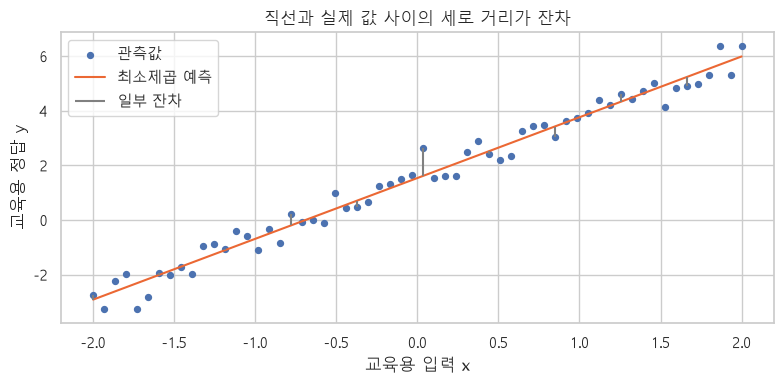

**실행 결과와 그래프 읽기**

기울기는 x가 1 증가할 때 예측이 얼마나 변하는지 나타냅니다. 세로선은 실제−예측 잔차입니다. 학습 계수가 가상의 참값 2.2·1.5와 정확히 같지 않은 것은 잡음과 유한 표본 때문입니다.


<a id="chapter-1-topic-22"></a>

### 알고리즘 상세 해설 · 경사하강법 — 손실이 줄어드는 방향으로 조금씩 이동

단일 입력 MSE에서 $\partial L/\partial w=\frac2n\sum x_i(\hat y_i-y_i)$,
$\partial L/\partial b=\frac2n\sum(\hat y_i-y_i)$입니다.
업데이트는 $w\leftarrow w-\eta\partial L/\partial w$, $b\leftarrow b-\eta\partial L/\partial b$입니다.
기울기가 증가 방향을 가리키므로 빼며, $\eta$는 한 번에 이동하는 정도인 학습률입니다.

**작동 순서**: 초기화 → 예측 → 오차 → 기울기 → 계수 갱신 → 반복.
학습률이 너무 작으면 느리고, 너무 크면 최솟값을 지나치며 진동하거나 발산합니다. 아래는 전체 표본을 매번 쓰는 배치 경사하강법입니다.
이 예제는 로지스틱 회귀의 실제 솔버나 HGB의 내부 구현을 그대로 재현한 것은 아닙니다.


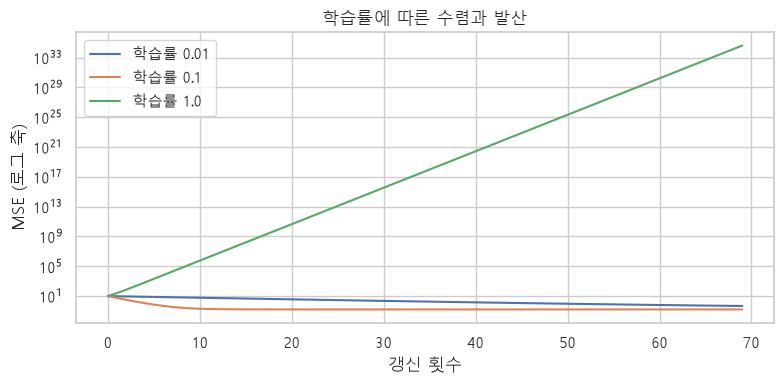

**실행 결과와 그래프 읽기**

곡선이 내려가면 학습 오차가 줄어듭니다. 큰 학습률 곡선이 올라가는 경우 계산을 더 반복한다고 해결되지 않습니다. 이 손실 곡선은 학습 수렴을 보여주며 일반화 성능을 보여주는 검증 곡선과 다릅니다.


<a id="chapter-1-topic-25"></a>

### 알고리즘 상세 해설 · 릿지 회귀 — 큰 계수에 비용을 부과하기

릿지는 제곱오차에 $\alpha\sum_jw_j^2$를 더해 최소화합니다. 계수 전체를 작게 만드는 압력을 **L2 정규화**라고 합니다.
상관된 입력 사이에서 계수가 지나치게 커지고 반대 부호로 상쇄되는 현상을 완화할 수 있습니다.

`alpha`가 클수록 축소 압력이 강합니다. 너무 크면 필요한 관계까지 줄여 과소적합합니다.
같은 계수 크기를 공정하게 비교하려면 입력 스케일을 맞추는 것이 중요합니다. 절편은 일반적으로 이 계수 벌점에서 제외됩니다.
릿지는 계수를 보통 정확히 0으로 만들지 않으므로 자동 변수 선택과 동일하지 않습니다.


,alpha,계수1,계수2,계수 L2 길이,학습 MSE
0,0.0001,4.0112,-1.3984,4.2480,0.1501
1,0.1000,1.5851,1.0255,1.8879,0.1524
2,10.0000,1.2090,1.2028,1.7054,0.1933
3,"1,000.0000",0.1400,0.1399,0.1979,5.5947


**실행 결과와 그래프 읽기**

alpha가 커질 때 계수 길이가 줄어드는지 확인합니다. 학습 MSE가 가장 작은 설정이 새 데이터에서도 최선이라는 보장은 없습니다. 실제 데이터에서는 CV로 alpha를 정해야 합니다.


<a id="chapter-1-topic-28"></a>

### 알고리즘 상세 해설 · 로지스틱 회귀 — 직선 점수를 확률로 바꾸기

이름에 회귀가 들어가지만 여기서는 이진 **분류** 알고리즘입니다.
먼저 $z=b+\sum w_jx_j$를 구하고 시그모이드 $p=1/(1+e^{-z})$로 0~1 범위로 바꿉니다.
z=0이면 p=0.5, z가 양수이면 p>0.5입니다. $\log(p/(1-p))=z$라서 계수는 확률 자체가 아니라 로그 오즈에 더해집니다.

**학습 목적**은 정규화 항이 포함된 로그손실 최소화입니다.
$-[y\log p+(1-y)\log(1-p)]$는 자신 있게 틀린 예측에 큰 벌점을 줍니다.
`C`는 정규화 강도의 역수로, **작을수록 더 강한 정규화**입니다. 릿지의 alpha와 방향이 반대입니다.
`max_iter`는 최대 반복 횟수이며 모델 복잡도를 직접 나타내는 값이 아닙니다.

`predict_proba`는 확률 점수, `predict`는 범주를 반환합니다. 확률 점수의 순위가 좋아도 확률값 자체가 잘 보정되었다는 보장은 없습니다.


,REAL 확률 p,실제 REAL일 때 로그손실,실제 FALSE일 때 로그손실
0,0.0100,4.6052,0.0101
1,0.1000,2.3026,0.1054
2,0.5000,0.6931,0.6931
3,0.9000,0.1054,2.3026
4,0.9900,0.0101,4.6052


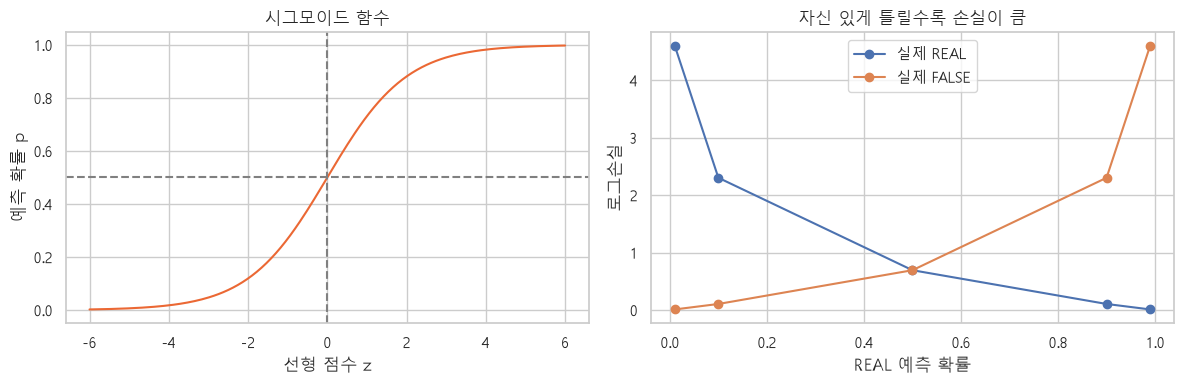

**실행 결과와 그래프 읽기**

실제 REAL인데 p=0.01이면 큰 손실을 받습니다. 임계값을 바꾸면 판정은 달라지지만 이미 학습한 계수와 확률 점수는 그대로입니다. 계수 한 단위 증가가 확률 1%p 증가를 뜻하지 않습니다.


<a id="chapter-1-topic-31"></a>

### 알고리즘 상세 해설 · 의사결정나무 — 불순도가 줄어드는 질문 찾기

나무는 “INTENSITY ≤ 특정 값인가?”처럼 입력 공간을 반복해서 둘로 나눕니다.
분류의 지니 불순도는 $G=1-\sum_k p_k^2$입니다. 두 범주가 반반이면 0.5, 한 범주만 있으면 0입니다.
좋은 분할은 **부모 불순도 − 자식 크기로 가중한 불순도**가 큰 분할입니다.

**순서**: 각 변수·경계 후보 검토 → 가장 큰 감소를 선택 → 각 자식에서 반복 → 정지조건에서 리프 생성.
전체 나무의 모든 조합을 한꺼번에 최적화하는 것이 아니라 현재 노드의 최선 분할을 고르는 탐욕적 방법입니다.
분류 리프는 학습 표본의 클래스 비율로 확률을 내고, 제곱오차 회귀 리프는 타깃 평균을 냅니다.

`max_depth`는 질문 단계 수, `min_samples_leaf`는 말단 노드에 남길 최소 표본 수입니다.
깊게 자라면 작은 차이까지 외울 수 있습니다. 스케일링은 대체로 필요 없지만 범주를 의미 없는 크기 순서로 넣지 않도록 주의합니다.


,경계,왼쪽 n,오른쪽 n,가중 자식 불순도,불순도 감소
0,2.5000,2,6,0.3333,0.1667
1,3.5000,3,5,0.2000,0.3000
2,4.5000,4,4,0.3750,0.1250
3,5.5000,5,3,0.2000,0.3000
4,6.5000,6,2,0.3333,0.1667


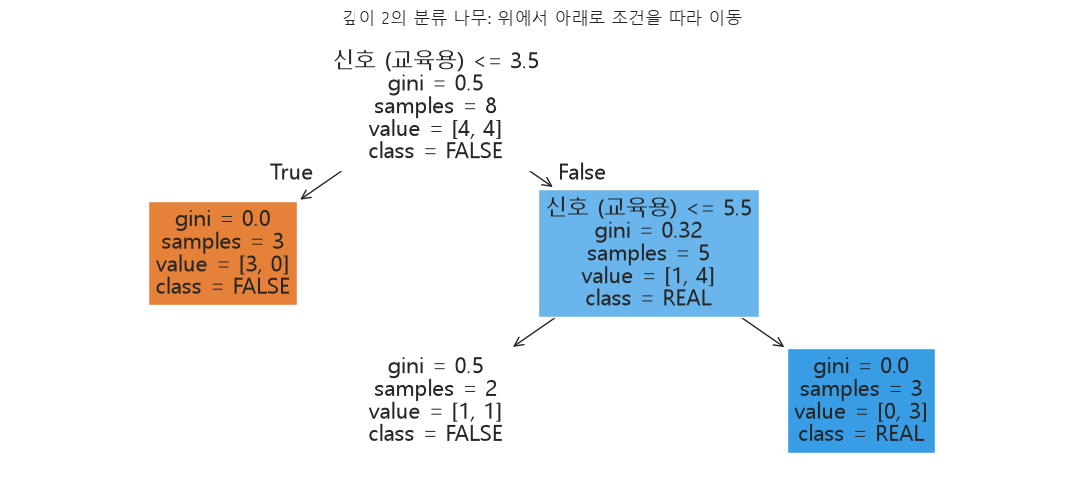

|--- signal <= 3.50
|   |--- class: 0
|--- signal >  3.50
|   |--- signal <= 5.50
|   |   |--- class: 0
|   |--- signal >  5.50
|   |   |--- class: 1



**실행 결과와 그래프 읽기**

첫 줄의 조건이 참이면 왼쪽으로 갑니다. gini는 혼합 정도이고 samples는 학습 표본 수입니다. value는 버전에 따라 개수 또는 정규화 비율로 표시될 수 있습니다. 양쪽 모두 같은 최선 감소를 갖는 경계가 있을 수 있어 유일한 정답 나무라고 보지 않습니다.


<a id="chapter-1-topic-34"></a>

### 알고리즘 상세 해설 · 랜덤포레스트 — 서로 다른 나무의 예측을 평균내기

하나의 나무는 표본이 조금 달라져도 구조가 크게 달라질 수 있습니다. 랜덤포레스트는 여러 나무의 변동을 평균으로 줄입니다.

1. 기본적으로 각 나무에 학습 행을 **복원추출**합니다. 한 행이 여러 번 들어가거나 빠질 수 있습니다.
2. 각 분할에서 `max_features`만큼의 변수 후보를 무작위로 살펴 나무 간 유사성을 줄입니다.
3. 분류는 나무별 클래스 확률을 평균하고, 회귀는 예측 수치를 평균합니다.

`n_estimators`는 나무 수입니다. 늘리면 계산·메모리가 증가하며 개선 폭이 점점 작아질 수 있습니다.
`max_features`를 줄이면 나무들이 다양해지지만 개별 나무는 약해질 수 있습니다.
OOB는 해당 나무의 복원추출에서 빠진 **행**을 이용합니다. 같은 로트의 다른 행이 학습에 있을 수 있어 새 로트 검증을 대체하지 못합니다.


,입력,첫 나무 확률,나무 확률 평균,나무 간 확률 SD
0,3.8000,1.0000,0.6333,0.4819
1,5.2000,0.0000,0.3000,0.4583
2,7.0000,1.0000,0.9667,0.1795


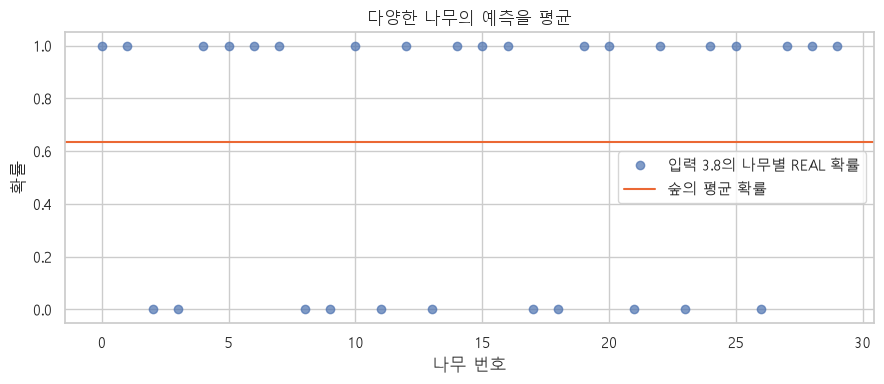

**실행 결과와 그래프 읽기**

나무별 점이 달라도 숲은 그 평균을 반환합니다. 나무 간 표준편차는 모델 내부의 다양성 지표이며 예측의 통계적 신뢰구간은 아닙니다. 같은 오류를 내는 나무만 모으면 평균의 이점도 제한됩니다.


<a id="chapter-1-topic-37"></a>

### 알고리즘 상세 해설 · 그래디언트 부스팅 — 부족한 예측을 순서대로 보완

랜덤포레스트는 나무를 독립적으로 다양하게 키우지만, 부스팅은 **현재 모델을 보완할 나무를 순서대로** 더합니다.
$F_m(x)=F_{m-1}(x)+\eta h_m(x)$에서 $\eta$는 학습률입니다.
제곱오차 회귀에서는 음의 손실 기울기가 잔차와 비례하므로 새 나무가 잔차를 학습합니다.
분류의 로그손실에서도 음의 기울기 방향을 이용하지만 “틀린 행만 다시 학습한다”는 설명은 정확하지 않습니다.

**아래 손실 최소화 실험**: 평균 예측으로 시작 → 실제−현재예측 잔차 계산 → 깊이 2 나무로 잔차 학습 → 0.25배만 더하기.
작은 학습률은 보통 더 많은 반복이 필요합니다. 반복이 너무 많으면 검증 성능이 떨어질 수 있어 학습 손실만 보고 정하지 않습니다.


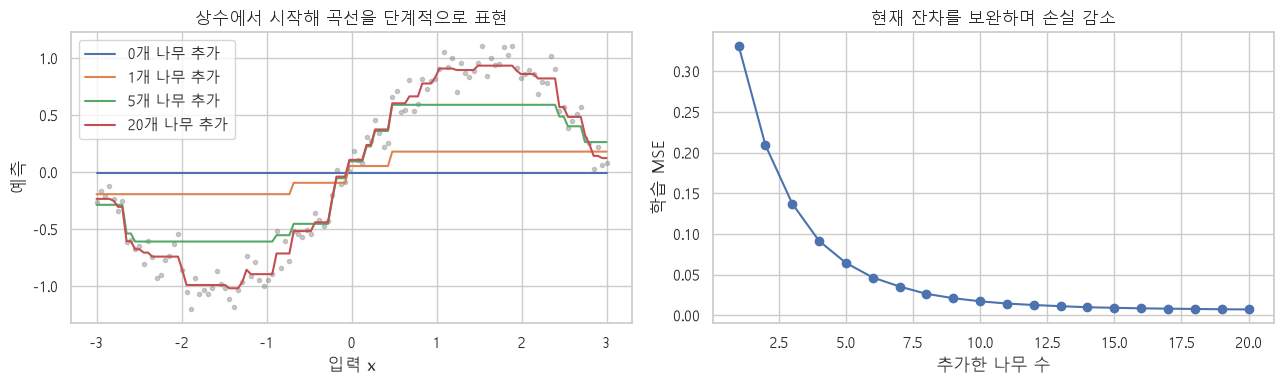

**실행 결과와 그래프 읽기**

0단계는 수평선이고 나무를 더할수록 비선형 모양을 따라갑니다. 이것은 부스팅 원리를 보여주는 교육 구현입니다. HGB의 히스토그램·2차 정보·정규화 등 내부 최적화를 그대로 구현한 것은 아닙니다.


<a id="chapter-1-topic-40"></a>

### 알고리즘 상세 해설 · HistGradientBoosting — 값들을 구간으로 모아 빠르게 탐색

HGB는 연속 입력값을 제한된 수의 구간(bin)으로 요약하여 분할 후보를 평가하는 부스팅입니다.
구간별 기울기와 곡률 정보를 모으면 원래 모든 값의 후보를 매번 검토하는 것보다 계산을 줄일 수 있습니다.
나무를 추가한다는 원리는 앞 실습과 이어지지만 내부 계산은 더 정교합니다.

| 설정 | 의미 | 지나치게 키우거나 줄이면 |
|---|---|---|
| learning_rate | 새 나무의 반영 비율 | 너무 크면 불안정, 너무 작으면 반복 증가 |
| max_iter | 최대 부스팅 단계 수 | 많으면 시간 증가·과적합 가능 |
| max_leaf_nodes | 나무 하나의 최대 말단 수 | 많으면 복잡한 규칙과 작은 패턴 학습 |
| min_samples_leaf | 말단 최소 표본 | 크면 안정적이나 세부 관계를 놓칠 수 있음 |
| l2_regularization | 말단 값에 대한 L2 벌점 | 크면 강한 축소 |
| max_bins | 입력별 구간 수 상한 | 더 정밀한 후보와 계산량의 절충 |

기본 조기종료는 행 단위 내부 검증을 사용할 수 있습니다. 이 교재는 새 로트 평가와 기준을 맞추기 위해 `early_stopping=False`로 두고 반복 수를 그룹 CV에서 비교합니다.
아래 분위수 구간화는 직관용 예시이며 HGB 내부 구간 경계를 복제하지 않습니다.


,교육용 원값,분위수 구간 (개념 예시)
0,1.0000,"(0.999, 2.75]"
1,2.0000,"(0.999, 2.75]"
2,2.0000,"(0.999, 2.75]"
3,3.0000,"(2.75, 6.5]"
4,4.0000,"(2.75, 6.5]"
5,5.0000,"(2.75, 6.5]"
6,8.0000,"(6.5, 16.25]"
7,10.0000,"(6.5, 16.25]"
8,15.0000,"(6.5, 16.25]"
9,20.0000,"(16.25, 100.0]"


원값 고유 수: 11 구간 수: 4


**실행 결과와 그래프 읽기**

한 구간에 여러 값이 모입니다. 구간 수를 줄이면 탐색이 단순해지지만 같은 구간 안 차이는 제한적으로 표현됩니다. HGB가 모든 데이터에서 RF보다 좋다는 뜻은 아니므로 실제 비교가 필요합니다.


---

<a id="chapter-2"></a>

## 2장. 문제 정의 & 데이터 준비

> **이 장의 목표**
> - 비즈니스 목적에서 타깃과 특성을 정한다.
> - 누수 변수를 찾아 제거한다.

[전체 목차](#contents) · [이전 장](#chapter-1) · [다음 장](#chapter-3)

**이 장의 개념과 실습**

- [2-1. 왜 이 두 과제인가?](#chapter-2-topic-44)
- [2-2. 변수 역할 정하기 — "예측하는 시점에 이 값을 알 수 있는가?"](#chapter-2-topic-47)


<a id="chapter-2-topic-44"></a>

### 2-1. 왜 이 두 과제인가?

| 과제 | 현장 문제 | 모델이 하는 일 | 기대 효과 |
|---|---|---|---|
| **분류** | 검사 장비가 잡은 결함의 44%가 가성결함(노이즈). 엔지니어가 하나하나 리뷰해야 함 | 리뷰 전에 REAL / FALSE 확률 계산 | **리뷰 공수 절감**, 진성결함 놓침 최소화 |
| **회귀** | 정확한 결함 크기는 리뷰 장비(SEM)로 다시 재야 함 | 검사 신호만으로 크기 추정 | 큰 결함 우선 리뷰, 크기 등급 자동 분류 |


**실습 프롬프트 P02 — 데이터 읽기와 타깃**

> CSV를 현재/상위 폴더에서 찾아 원본 복사본을 만들고 키 중복 수를 출력해줘. 검사 회차가 없어 임의 삭제하지 마.
>
> IS_DEFECT를 REAL=1/FALSE=0으로 만들고 양수 SIZE_D의 log10을 회귀 타깃으로 만들어줘.


읽은 파일: C:\Users\ryp16\CodexProjects\반도체_웨이퍼_basic_raw_data.csv 행·열: (63908, 25)
키 중복 추가 기록: 21 — 검사 회차가 없어 원인을 단정하지 않고 유지


,기록 수
IS_DEFECT,
REAL,35848
FALSE,28060


<a id="chapter-2-topic-47"></a>

### 2-2. 변수 역할 정하기 — "예측하는 시점에 이 값을 알 수 있는가?"

| 질문 | 예 → | 아니오 → |
|---|---|---|
| 예측 시점(검사 직후)에 이 값을 알 수 있는가? | 특성 후보 | **누수 → 제외** |
| 개체를 구분하는 이름표일 뿐인가? | **ID → 제외** | 특성 후보 |
| 타깃을 계산하는 데 쓰였거나 타깃과 사실상 같은가? | **누수 → 제외** | 특성 |


**실습 프롬프트 P03**

> **[맥락]** df의 열은 Step, Step_desc, Lot Name, Slot No, Defect No, Class, IS_DEFECT, SIZE_X, SIZE_Y,
>
> DEFECT_AREA, SIZE_D, INTENSITY, POLARITY, ENERGY_PARAM, MDAT_OFFSET, MDAT_GL, MDAT_NOISE, RADIUS,
>
> ANGLE, ALIGNRATIO, SPOTLIKENESS, PATCHNOISE, RELATIVEMAGNITUDE, ACTIVERATIO, PATCHDEFECTSIGNAL이야.
>
> **[작업]** 변수 역할표(DataFrame)를 만들어줘.
> - 열: 변수, 그룹(식별/분류결과/크기/신호/형상/위치/공정), 분류 과제 사용(O/X + 이유),
>
>       회귀 과제 사용(O/X + 이유)
> - 규칙: Step·Lot Name·Slot No·Defect No는 ID라 제외(Step은 Step_desc와 같은 정보),
>
>         Class·IS_DEFECT는 분류 타깃 누수, SIZE_X·SIZE_Y·DEFECT_AREA·SIZE_D는 회귀 타깃 누수.
>
>         Step_desc와 POLARITY는 범주형 특성.
>
> **[출력]** 표를 그대로 보여주고, 분류용 특성 리스트 FEAT_CLF와 회귀용 FEAT_REG,
>
>        범주형 리스트 CAT_COLS를 만들어 개수를 출력해줘.


,변수,그룹,분류 과제,회귀 과제
0,Step,식별,X ID,X ID
1,Lot Name,식별,X ID,X ID
2,Slot No,식별,X ID,X ID
3,Defect No,식별,X ID,X ID
4,Class,분류결과,X 타깃 누수,X 리뷰 후에야 앎
5,IS_DEFECT,분류결과,X 타깃 누수,X 리뷰 후에야 앎
6,SIZE_X,크기,O 특성,X 타깃(크기) 누수
7,SIZE_Y,크기,O 특성,X 타깃(크기) 누수
8,DEFECT_AREA,크기,O 특성,X 타깃(크기) 누수
9,SIZE_D,크기,O 특성,X 타깃(크기) 누수


분류 특성 19개 / 회귀 특성 15개 / 범주형 ['Step_desc', 'POLARITY']


**실습 프롬프트 P04**

> **[맥락]** df에 Class(결함 분류 코드)와 is_real(1=REAL)이 있어.
>
> **[작업]** Class가 왜 '누수 변수'인지 숫자로 보여줘.
> 1. Class별 행 수와 is_real 평균(진성결함 비율)을 표로 만들어줘.
> 2. Class 하나만 알면 is_real을 몇 % 맞힐 수 있는지 계산해줘
>
>    (각 Class에서 다수 쪽으로 예측했을 때의 정확도).
>
> **[출력]** 표 + "Class만으로 정확도 xx.x%" 한 줄.


Class,9,10,14,17,20,21,22,28,39,56,99
행수,"28,060.0000","6,143.0000",495.0000,931.0000,"2,269.0000","14,215.0000",460.0000,"1,022.0000","3,469.0000","1,549.0000","5,295.0000"
진성비율,0.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000


Class만으로 is_real 정확도 : 100.0%  →  Class는 정답 그 자체(누수)이므로 제외


> **이번 실행 결과 해석**
> Class별 진성 비율과 정확도는 바로 위 실행 표에서 확인합니다. 높은 연관성 자체만으로 누수라고 단정하는 것이 아니라, 이 과제에서는 리뷰 후 생성되는 코드라는 전제로 입력에서 제외합니다. 생성 시점은 현장 확인이 필요합니다.


**실습 프롬프트 P05**

> **[맥락]** 회귀 타깃은 log_size = log10(SIZE_D)야.
>
> **[작업]** SIZE_X, SIZE_Y, DEFECT_AREA가 회귀에서 누수인 이유를 보여줘.
> 1. SIZE_D와 SIZE_X, SIZE_Y, DEFECT_AREA의 피어슨 상관계수, 스피어만 상관계수를 표로.
> 2. SIZE_D와 max(SIZE_X, SIZE_Y)가 같은 행의 비율(%)을 계산해줘.
>
> **[출력]** 표 + 비율 한 줄.


,피어슨 r,스피어만 ρ
SIZE_X,0.8820,0.8710
SIZE_Y,0.7100,0.9170
DEFECT_AREA,0.4280,0.8410


SIZE_D == max(SIZE_X, SIZE_Y) 인 행 : 100.0%  →  크기 변수는 정답을 계산하는 재료(누수)


> **이번 실행 결과 해석**
> 크기 변수 사이의 계산 관계는 위 수치로 확인합니다. 이번 회귀 과제는 크기 정보 없이 크기를 추정하는 조건이므로 크기 관련 입력을 제외합니다.


**실습 프롬프트 P06**

> **[맥락]** df에 is_real(0/1), SIZE_D(µm), log_size(log10 SIZE_D)가 있어.
>
> **[작업]** 두 타깃의 분포를 1×3 그래프로 그려줘.
> 1. is_real 막대그래프 (FALSE=파랑 C_FALSE, REAL=주황 C_REAL, 막대 위에 비율 % 표시)
> 2. SIZE_D 히스토그램 (원래 단위)
> 3. log_size 히스토그램
>
> **[조건]** 2·3번 제목에 왜도(skew) 값을 넣어 로그 변환 효과가 보이게 해줘.
>
> **[출력]** 그래프 + 2줄 해석.


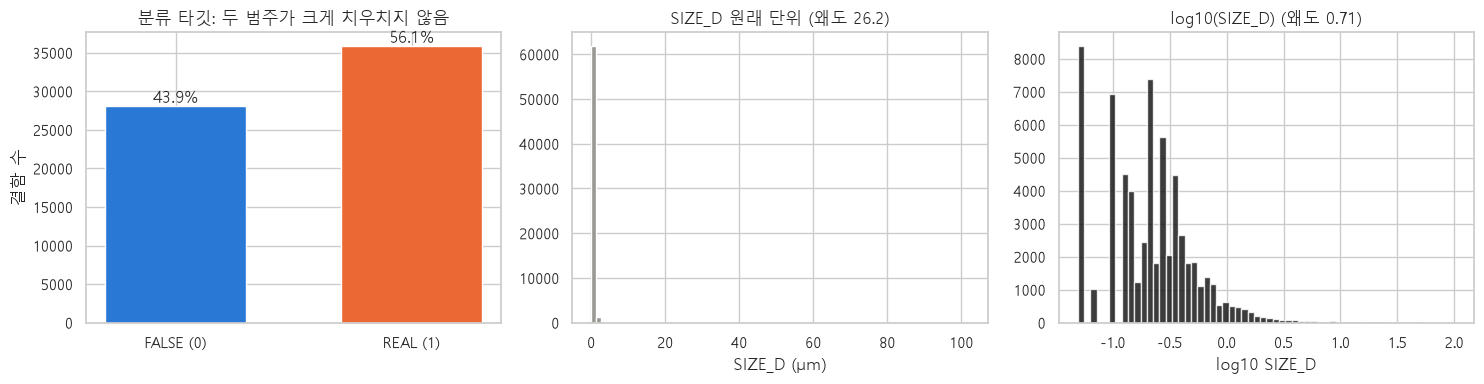

> **이번 실행 결과 해석**
> 로그 타깃의 분포는 학습 목적을 이해하기 위한 확인입니다. 3일차의 EDA를 반복하거나 이 그림만으로 모델을 결정하지 않습니다.


---

<a id="chapter-3"></a>

## 3장. 데이터 분할 & 전처리 파이프라인

> **이 장의 목표**
> - 학습/검증/테스트 데이터의 역할과 교차검증을 설명할 수 있다.
> - 같은 로트가 섞이면 성능이 부풀려지는 이유(그룹 누수)를 이해한다.
> - Pipeline으로 전처리 누수를 막는다.

[전체 목차](#contents) · [이전 장](#chapter-2) · [다음 장](#chapter-4)

**이 장의 개념과 실습**

- [3-1. 데이터를 나누는 이유](#chapter-3-topic-60)
- [3-2. 전처리 파이프라인 — 전처리도 '학습'이다](#chapter-3-topic-68)

**알고리즘 상세 해설 바로가기**

- [행 분할과 로트 분할 — 알고리즘보다 먼저 정할 평가 단위](#chapter-3-topic-64)
- [Pipeline — 학습해야 할 전처리도 모델과 함께 묶기](#chapter-3-topic-71)


<a id="chapter-3-topic-60"></a>

### 3-1. 데이터를 나누는 이유

```
 전체 데이터 (로트 457개)
 ├── 학습용 80% ──────────────────────────────┐   ← 모델 선택·튜닝·임계값 결정
 │    └─ 교차검증 (GroupKFold 설정한 겹수의)            │
 │        [검증][학습][학습][학습][학습]  1회차 │
 │        [학습][검증][학습][학습][학습]  2회차 │
 │        ...                    5회 평균 점수 │
 └── 테스트용 20% ── 마지막에 단 한 번 ─────┘   ← "처음 보는 로트"에서의 성능
```

| 데이터 | 용도 | 주의 |
|---|---|---|
| **학습 (train)** | 모델이 규칙을 배움 | |
| **검증 (validation / 교차검증)** | 모델·하이퍼파라미터·임계값 선택 | 여러 번 사용 가능 |
| **테스트 (test)** | 최종 성능 보고 | **딱 한 번**. 보고 나서 모델을 바꾸면 테스트가 아님 |


#### 왜 '로트' 단위로 나누나? — 그룹 누수

같은 로트의 웨이퍼는 같은 장비·같은 날·같은 조건을 거쳐 결함 특성이 비슷합니다.
행을 무작위로 나누면 **같은 로트의 형제 결함이 학습과 테스트에 동시에** 들어가서 모델이 "로트의 특징"을 외워 점수가 부풀려집니다.
실제 운영에서는 **새로 들어오는 로트**를 판정해야 하므로, 로트 단위로 나눠야 정직한 점수입니다.


**실습 프롬프트 P07**

> **[맥락]** df, FEAT_CLF, FEAT_REG, is_real, log_size가 준비되어 있어. 로트 열은 'Lot Name'이야.
>
> **[작업]**
> 1. GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)로
>
>    'Lot Name' 기준 학습/테스트 인덱스(idx_tr, idx_te)를 만들어줘.
> 2. 분류용 Xc_tr, Xc_te, yc_tr, yc_te / 회귀용 Xr_tr, Xr_te, yr_tr, yr_te,
>
>    학습용 그룹 g_tr(Lot Name)을 만들어줘. 두 과제는 같은 분할을 공유해.
> 3. 범주형이 아닌 정수형 열은 float로 바꿔줘 (부분 의존도 함수가 정수 열을 지원하지 않음).
> 4. 검증: 학습·테스트 로트가 겹치는지(교집합 개수) 확인해줘.
>
> **[출력]** 표: 구분(학습/테스트)별 행 수, 로트 수, REAL 비율(%), log_size 평균. + 겹치는 로트 수.


,행 수,로트 수,REAL 비율(%),log_size 평균
학습,52004,365,56.2880,-0.6780
테스트,11904,92,55.2420,-0.7000


학습·테스트에 동시에 있는 로트 수 : 0


<a id="chapter-3-topic-64"></a>

### 알고리즘 상세 해설 · 행 분할과 로트 분할 — 알고리즘보다 먼저 정할 평가 단위

새 로트에 적용할 모델이라면 검증에서도 처음 보는 로트를 만나야 합니다. 그룹 분할은 이를 흉내 냅니다.
`test_size=0.2`는 로트 수의 비율이므로 행 수가 정확히 20%일 필요는 없습니다.
GroupKFold는 각 로트가 한 검증 폴드에만 속하도록 나눕니다. 분류 비율을 자동으로 일정하게 맞춘다고 보장하지 않습니다.

**세 종류의 누수**: 타깃을 알려주는 입력, 학습·검증 사이 동일 로트 공유, 검증까지 포함해 미리 전처리·변수 선택.
로트 분할은 미래 시간·새 설비·다른 제품군에 대한 모든 일반화를 보장하지 않습니다. 시간 열이 없어 미래 검증을 수행하지 못합니다.


,폴드,학습 행,검증 행,학습 로트,검증 로트,겹침,검증 REAL 비율
0,1,34654,17350,243,122,0,0.5475
1,2,34677,17327,244,121,0,0.5639
2,3,34677,17327,243,122,0,0.5773


**실행 결과와 그래프 읽기**

각 행의 겹침이 0인지 확인합니다. 표본 수와 REAL 비율이 폴드마다 다른 만큼 성능도 달라질 수 있습니다. CV 표준편차는 폴드 간 변동이며 곧바로 95% 신뢰구간으로 해석하지 않습니다.


> **이번 실행 결과 해석**
> 학습·테스트 로트의 겹침은 0이어야 합니다. 표의 실제 행 수·로트 수·범주 비율을 확인합니다.


<a id="chapter-3-topic-68"></a>

### 3-2. 전처리 파이프라인 — 전처리도 '학습'이다

| 전처리 | 왜 필요한가 | 어떤 모델에 |
|---|---|---|
| **원-핫 인코딩** | 범주(PC/RMG/CBCMP)를 0/1 열로 바꿈. 숫자 코드(1,2,3)로 두면 "크기 순서"로 오해 | 모든 모델 |
| **표준화 (StandardScaler)** | (x − 평균) / 표준편차. 단위가 다른 변수를 같은 척도로 | 선형 모델 (트리는 불필요) |

**스케일러의 평균·표준편차도 데이터에서 '배운' 값**입니다. 전체 데이터로 `fit` 하면 테스트 정보가 학습에 새어 들어갑니다.
→ `Pipeline` 으로 묶으면 교차검증의 각 회차마다 **학습 부분으로만** fit 되어 자동으로 안전합니다.

```
Pipeline ─┬─ ColumnTransformer ─┬─ 수치형 → StandardScaler (선형 모델만)
          │                     └─ 범주형 → OneHotEncoder
          └─ 모델 (LogisticRegression, RandomForest, ...)
```


**실습 프롬프트 P08**

> **[맥락]** 범주형 열 리스트 CAT_COLS = ['Step_desc', 'POLARITY']가 있어.
>
> **[작업]** 전처리기를 만드는 함수 make_prep(features, scale)를 작성해줘.
> - features 중 CAT_COLS에 있는 열은 OneHotEncoder(handle_unknown='ignore', sparse_output=False),
>
>   나머지 수치형 열은 scale=True면 StandardScaler, False면 그대로 통과('passthrough').
> - ColumnTransformer의 verbose_feature_names_out=False로 해서 열 이름이 깔끔하게 나오게 해줘.
>
> **[검증]** make_prep(FEAT_CLF, True)를 Xc_tr에 fit_transform 해서
> 1. 변환 전/후 열 개수, 2. 변환 후 열 이름, 3. 수치형 열 3개의 평균·표준편차(≈0, 1인지)를 출력해줘.


변환 전 19열 → 변환 후 23열
변환 후 열 이름 : ['SIZE_X', 'SIZE_Y', 'DEFECT_AREA', 'SIZE_D', 'INTENSITY', 'ENERGY_PARAM', 'MDAT_OFFSET', 'MDAT_GL', 'MDAT_NOISE', 'RELATIVEMAGNITUDE', 'PATCHDEFECTSIGNAL', 'ALIGNRATIO', 'SPOTLIKENESS', 'PATCHNOISE', 'ACTIVERATIO', 'RADIUS', 'ANGLE', 'Step_desc_CBCMP', 'Step_desc_PC', 'Step_desc_RMG', 'POLARITY_-1', 'POLARITY_0', 'POLARITY_1']


,SIZE_D,INTENSITY,RADIUS
mean,-0.0000,0.0000,-0.0000
std,1.0000,1.0000,1.0000


<a id="chapter-3-topic-71"></a>

### 알고리즘 상세 해설 · Pipeline — 학습해야 할 전처리도 모델과 함께 묶기

`fit`은 평균·표준편차·범주 목록을 배웁니다. `transform`은 이미 배운 값으로 변환합니다.
Pipeline을 교차검증 함수에 전달하면 매 폴드마다 새로운 복사본이 해당 학습 부분만으로 전처리를 배웁니다.
변환해 둔 전체 학습 행렬 Z를 CV에 넣으면 그 CV의 검증 폴드가 전처리에 참여하므로 여기서는 Z를 확인용으로만 사용합니다.

원-핫은 범주를 0/1 열로 만들지만 그 열은 StandardScaler 대상이 아닙니다. 따라서 선형 계수에서 수치형은 1 SD, 범주는 상태 변화라는 해석 차이가 있습니다.
`handle_unknown='ignore'`는 새 범주를 해당 블록의 0으로 표시합니다. 오류가 없다는 것이 새 범주에서 예측이 믿을 만하다는 뜻은 아닙니다.


스케일러 평균이 학습 입력 평균과 일치: True


,SIZE_X,SIZE_Y,DEFECT_AREA,SIZE_D,INTENSITY,ENERGY_PARAM,MDAT_OFFSET,MDAT_GL,MDAT_NOISE,RELATIVEMAGNITUDE,PATCHDEFECTSIGNAL,ALIGNRATIO,SPOTLIKENESS,PATCHNOISE,ACTIVERATIO,RADIUS,ANGLE,Step_desc_CBCMP,Step_desc_PC,Step_desc_RMG,POLARITY_-1,POLARITY_0,POLARITY_1
0,-0.0416,-0.0706,-0.0635,-0.0905,-0.4443,-0.0447,-0.3838,-0.7384,-0.2069,-0.4497,-0.1562,0.3560,0.3580,-0.4795,0.6556,1.0754,1.5727,0.0000,1.0000,0.0000,0.0000,0.0000,1.0000
1,-0.0083,0.0258,-0.0610,-0.0335,0.6688,1.6481,1.0111,-0.6205,-0.5969,0.7589,1.0107,0.3560,1.0460,-0.0664,0.6556,-2.3845,1.0881,0.0000,1.0000,0.0000,0.0000,0.0000,1.0000
2,-0.1411,-0.2156,-0.0654,-0.1762,-0.6404,-0.9865,-0.3776,-0.4448,-0.7811,-0.5950,-0.2448,0.3459,2.8783,-0.6989,0.6556,0.3181,1.5447,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000


새 공정의 원-핫 블록: [[0. 0. 0.]]


**실행 결과와 그래프 읽기**

평균이 일치하는 것은 학습 자료에서 스케일을 배웠기 때문입니다. 실제 검증에서는 이 prep 객체가 아니라 각 Pipeline 안의 새 전처리 객체가 해당 폴드에서 학습됩니다.


> **결과 해석**
> - 범주형 2개(공정 3종, 극성 3종)가 6개의 0/1 열로 바뀌어 열 수가 늘었습니다.
> - 표준화된 열은 평균 0, 표준편차 1이 됩니다. 이 값은 **학습 데이터로만** 계산되었고, 테스트에는 같은 평균·표준편차가 그대로 적용됩니다.


**실습 프롬프트 P09**

> **[맥락]** Xc_tr, yc_tr, g_tr(로트), make_prep 함수가 있어.
>
> **[작업]** '그룹 누수'가 점수를 얼마나 부풀리는지 실험해줘.
> - 모델: Pipeline(make_prep(FEAT_CLF, False) + HistGradientBoostingClassifier(random_state=RANDOM_STATE))
> - 방법 A: KFold(5, shuffle=True, random_state=RANDOM_STATE) — 행 무작위 분할
> - 방법 B: GroupKFold(5) + groups=g_tr — 로트 단위 분할
> - 지표: ROC-AUC, 정확도
>
> **[출력]** 방법별 평균·표준편차 표와 "무작위 분할이 AUC를 x.xxx 높게 추정" 한 줄.


,AUC 평균,AUC 표준편차,정확도 평균
A. 무작위 KFold,0.9500,0.0019,0.8912
B. 로트 GroupKFold,0.9483,0.0089,0.8905


무작위 CV AUC - 그룹 CV AUC = +0.0017 (항상 양수인 것은 아님)


> **이번 실행 결과 해석**
> 무작위 분할과 로트 분할의 점수 차이는 위 계산값을 읽습니다. 항상 일정한 방향의 차이가 생기는 것은 아닙니다. 배포 대상이 새 로트이므로 그룹 검증을 사용합니다.


---

<a id="chapter-4"></a>

## 4장. 평가지표 선택

> **이 장의 목표**
> - 분류·회귀 지표의 정의와 계산법을 안다.
> - 문제의 목적(비용)에 맞는 지표를 고를 수 있다.

[전체 목차](#contents) · [이전 장](#chapter-3) · [다음 장](#chapter-5)

**이 장의 개념과 실습**

- [4-1. 분류 지표 — 혼동행렬에서 시작](#chapter-4-topic-79)
- [4-2. 회귀 지표](#chapter-4-topic-80)
- [4-3. 이 노트북의 지표 선택 (결정 사항)](#chapter-4-topic-92)

**알고리즘 상세 해설 바로가기**

- [평가 지표를 손실·확률·판정과 구분하기](#chapter-4-topic-88)


<a id="chapter-4-topic-79"></a>

### 4-1. 분류 지표 — 혼동행렬에서 시작

```
                       예측
                 FALSE(0)     REAL(1)
 실제 FALSE(0) │   TN     │    FP    │   ← FP: 가성을 진성으로 → 쓸데없는 리뷰 (비용 小)
 실제 REAL(1)  │   FN     │    TP    │   ← FN: 진성을 놓침 → 불량 유출 (비용 大)
```

| 지표 | 공식 | 질문 | 이 문제에서 |
|---|---|---|---|
| **정확도 Accuracy** | (TP+TN) / 전체 | 전체 중 몇 % 맞혔나? | 범주 비율에 속기 쉬움 |
| **정밀도 Precision** | TP / (TP+FP) | REAL이라 한 것 중 진짜 REAL은? | 리뷰 효율 |
| **재현율 Recall (민감도)** | TP / (TP+FN) | 진짜 REAL 중 몇 %를 잡았나? | **놓치면 안 됨** |
| **특이도 Specificity** | TN / (TN+FP) | 진짜 FALSE 중 몇 %를 걸러냈나? | **리뷰 절감률** |
| **F1** | 2·P·R / (P+R) | 정밀도와 재현율의 조화평균 | 임계값 하나에서의 요약 |
| **ROC-AUC** | ROC 곡선 아래 면적 | 무작위 REAL 1개가 무작위 FALSE 1개보다 높은 점수를 받을 확률 | **모델 비교** (임계값 무관) |
| **PR-AUC (AP)** | PR 곡선 아래 면적 | 정밀도-재현율 균형 전체 | 불균형이 클 때 유용 |


<a id="chapter-4-topic-80"></a>

### 4-2. 회귀 지표

| 지표 | 공식 | 단위 | 특징 |
|---|---|---|---|
| **MAE** | 평균 \|y − ŷ\| | µm | 직관적, 이상치에 덜 민감 |
| **RMSE** | √평균(y − ŷ)² | µm | 큰 오차에 벌점 ↑ (이상치에 민감) |
| **R² (결정계수)** | 1 − SSE / SST | 없음 | "평균으로 예측" 대비 몇 % 설명했나. 0=기준모델, 1=완벽 |
| **MdAPE** | 중앙값 \|y − ŷ\| / y × 100 | % | 상대 오차. 0.1µm와 10µm 결함을 공평하게 |


**실습 프롬프트 P10**

> **[작업]** 혼동행렬과 분류 지표를 손으로 계산하는 연습 코드를 만들어줘.
> - 실제값 y_true = [1,1,1,1,1,1,0,0,0,0], 예측값 y_pred = [1,1,1,1,0,0,1,0,0,0]
> 1. TP, FP, FN, TN을 numpy 비교 연산으로 직접 세줘.
> 2. 정확도, 정밀도, 재현율, 특이도, F1을 공식으로 직접 계산해줘.
> 3. 같은 값을 sklearn(accuracy_score, precision_score, recall_score, f1_score)으로 계산해
>
>    '직접 계산'과 'sklearn' 두 열로 나란히 비교하는 표를 만들어줘 (특이도는 recall_score(pos_label=0)).


TP=4, FN=2, FP=1, TN=3


,직접 계산,sklearn
정확도,0.7000,0.7000
정밀도,0.8000,0.8000
재현율,0.6670,0.6670
특이도,0.7500,0.7500
F1,0.7270,0.7270


**실습 프롬프트 P11**

> **[맥락]** Xc_tr, yc_tr(REAL 56%)가 있어.
>
> **[작업]** '정확도의 함정'을 보여줘.
> - DummyClassifier(strategy='most_frequent')로 모두 REAL이라고 예측하는 모델을 학습 데이터로 fit.
> - 같은 학습 데이터에서 정확도, 재현율, 특이도, F1, ROC-AUC를 계산해 한 줄 표로.
>
>   (ROC-AUC는 predict_proba의 1열 사용)
>
> **[출력]** 표 + "아무것도 배우지 않아도 정확도 xx%" 한 줄.


,정확도,재현율(REAL),특이도(FALSE),F1,ROC-AUC
Dummy(모두 REAL),0.5630,1.0000,0.0000,0.7200,0.5000


> **이번 실행 결과 해석**
> Dummy의 재현율이 높아도 FALSE를 걸러내지 못할 수 있습니다. 실제 출력에서 특이도와 함께 비교합니다.


**실습 프롬프트 P12**

> **[작업]** 회귀 지표 MAE와 RMSE가 이상치에 어떻게 다르게 반응하는지 보여줘.
> - 실제값 y = [0.10, 0.15, 0.20, 0.25, 0.30] (µm)
> - 예측 A = 실제값 + 0.05 (모든 점에서 조금씩 틀림)
> - 예측 B = 실제값과 같고 마지막 하나만 0.30 → 0.55 (한 점만 크게 틀림)
> - 각 예측의 MAE, RMSE, R²를 계산해 표로 비교해줘.
>
> **[출력]** 표 + 해석 2줄 (오차 총합이 같아도 RMSE는 B를 더 나쁘게 본다).


,MAE,RMSE,R²
A: 모두 0.05씩,0.0500,0.0500,0.5000
B: 한 점만 0.25,0.0500,0.1118,-1.5000


<a id="chapter-4-topic-88"></a>

### 알고리즘 상세 해설 · 평가 지표를 손실·확률·판정과 구분하기

분류의 ROC-AUC는 순위 능력이고, 정확도·재현율·정밀도는 임계값을 적용한 판정의 품질입니다.
이 교재의 `average_precision_score`는 **AP(Average Precision)**입니다. PR 곡선을 사다리꼴 적분한 값과 항상 같지 않아 PR_AUC 대신 AP로 표기합니다.

회귀에서 $R^2=1-\sum(y-\hat y)^2/\sum(y-\bar y)^2$입니다. 1은 완벽, 0은 평가 표본 평균 예측 수준, 음수는 그보다 나쁩니다.
음수 R²에 절댓값을 씌우면 나쁜 모델을 좋은 모델로 바꾸어 보고하는 오류가 됩니다.
scikit-learn의 `neg_mean_absolute_error`처럼 이름에 neg가 붙은 점수나 부호 반전 scorer만 다시 부호를 바꿉니다.


직접 계산 R²: -73.5 라이브러리: -73.5


,임계값,AUC,정확도,재현율
0,0.3000,1.0000,0.7500,1.0000
1,0.5000,1.0000,1.0000,1.0000
2,0.7000,1.0000,0.7500,0.5000


**실행 결과와 그래프 읽기**

임계값을 바꾸어도 동일 확률 점수의 AUC는 같습니다. R²가 매우 큰 음수로 나오는 예제는 오류가 아니라 평가 평균보다 훨씬 나쁜 예측이라는 뜻입니다.


> **이번 실행 결과 해석**
> MAE가 같아도 큰 오차 하나가 있는 경우 RMSE가 더 커질 수 있습니다. R²는 음수도 가능하며 그대로 보고합니다.


<a id="chapter-4-topic-92"></a>

### 4-3. 이 노트북의 지표 선택 (결정 사항)

| 과제 | 단계 | 지표 | 선택 이유 |
|---|---|---|---|
| **분류** | 모델 비교·튜닝 | **ROC-AUC** (보조: PR-AUC, F1) | 임계값과 무관하게 "REAL을 FALSE보다 높게 점수 매기는 능력"을 비교. 범주 비율 56:44에서 안정적 |
| | 운영 임계값 | **재현율(REAL) ≥ 98% 조건에서 특이도 최대** | 진성결함 놓침(FN)은 불량 유출 → 비용이 큼. 그 조건 안에서 가성결함을 최대한 걸러 리뷰 공수 절감 |
| **회귀** | 학습 | log10(SIZE_D) | 긴 꼬리 분포 → 로그로 오차를 상대적으로 만듦 |
| | 모델 비교 | **R²(로그 척도)**, **MAE(µm)**, **MdAPE(%)** | R²: 기준 모델 대비 설명력 / MAE: 현장 단위 / MdAPE: 크기와 무관한 상대 오차 |
| | 보조 | RMSE(µm) | 큰 결함에서의 대형 오차 감시 |


---

<a id="chapter-5"></a>

## 5장. 분류 모델링 — 진성/가성결함 판정

> **이 장의 목표**
> - 기준 모델부터 앙상블까지 교차검증으로 공정하게 비교한다.
> - 과적합 곡선과 학습 곡선을 읽는다.
> - 하이퍼파라미터를 튜닝하고 테스트 데이터로 최종 평가한다.
> - 현장 목적에 맞는 임계값을 정하고 오차를 분석한다.

[전체 목차](#contents) · [이전 장](#chapter-4) · [다음 장](#chapter-6)

**이 장의 개념과 실습**

- [5-1. 과적합을 눈으로 보기 — 검증 곡선 (Validation Curve)](#chapter-5-topic-104)
- [5-2. 하이퍼파라미터 튜닝 — RandomizedSearchCV](#chapter-5-topic-114)
- [5-3. 임계값 정하기 — 0.5는 정답이 아니다](#chapter-5-topic-121)
- [5-4. 테스트 데이터로 최종 평가 (단 한 번)](#chapter-5-topic-128)

**알고리즘 상세 해설 바로가기**

- [실제 웨이퍼 모델 설정을 읽는 법](#chapter-5-topic-96)
- [검증 곡선 — 깊이가 늘면 무엇이 좋아지고 나빠지는가?](#chapter-5-topic-107)
- [튜닝 — 후보 설정을 검증 데이터로 비교하기](#chapter-5-topic-117)
- [임계값 — 확률 모델과 리뷰 규칙을 분리하기](#chapter-5-topic-124)


**실습 프롬프트 P13**

> **[맥락]** make_prep(features, scale), FEAT_CLF, RANDOM_STATE가 있어.
>
> **[작업]** 비교할 분류 모델 5개를 딕셔너리 clf_models로 만들어줘. 모두 Pipeline(prep + model) 형태.
> 1. 'Dummy'           : DummyClassifier(strategy='prior')                  — prep scale=False
> 2. '로지스틱 회귀'    : LogisticRegression(max_iter=2000)                  — prep scale=True (선형 모델은 표준화 필요)
> 3. '의사결정나무'     : DecisionTreeClassifier(max_depth=8)                — scale=False
> 4. '랜덤포레스트'     : RandomForestClassifier(n_estimators=200, min_samples_leaf=2, n_jobs=-1) — scale=False
> 5. '그래디언트부스팅' : HistGradientBoostingClassifier()                   — scale=False
>
> 모든 모델에 random_state=RANDOM_STATE (Dummy·로지스틱 제외).
>
> **[출력]** 모델 이름과 Pipeline 구조를 출력해줘.


Dummy      → ['ColumnTransformer', 'DummyClassifier']
로지스틱 회귀    → ['ColumnTransformer', 'LogisticRegression']
의사결정나무     → ['ColumnTransformer', 'DecisionTreeClassifier']
랜덤포레스트     → ['ColumnTransformer', 'RandomForestClassifier']
그래디언트부스팅   → ['ColumnTransformer', 'HistGradientBoostingClassifier']


<a id="chapter-5-topic-96"></a>

### 알고리즘 상세 해설 · 실제 웨이퍼 모델 설정을 읽는 법

이제 작은 예제에서 배운 모델을 실제 데이터에 적용합니다. 모든 모델에 동일한 로트 분할을 사용합니다.
Dummy는 입력을 활용하지 않는 최소 비교 기준입니다. 복잡한 모델이 Dummy보다 얼마나 좋아지는지부터 봅니다.

| 모델 | 배우는 규칙 | 우선 조절할 설정 | 확인할 문제 |
|---|---|---|---|
| 로지스틱 | 선형 로그 오즈 | C, 수렴 반복 수 | 비선형 관계·수렴 |
| 나무 | 반복 임계값 분할 | max_depth, min_samples_leaf | 깊은 나무의 과적합 |
| RF | 다양한 나무의 확률 평균 | 나무 수, max_features, 리프 표본 | 계산량·상관된 나무 |
| HGB | 나무의 순차적 합 | learning_rate, 반복 수, 리프 수 | 과적합·정규화 |

분류 입력에 크기 변수가 포함됩니다. 따라서 실제 크기가 예측 시점에 이미 확보된다는 조건의 과제이며, “광학 신호만 사용하는 분류”라고 표현하지 않습니다.
회귀는 크기 변수를 제외하고 신호·형상·위치·공정을 사용합니다. 입력 확보 시점과 Class의 생성 절차는 현장 문서 확인이 필요합니다.


,모델,C,max_depth,n_estimators,max_features,max_iter,learning_rate,early_stopping
0,Dummy,해당 없음,해당 없음,해당 없음,해당 없음,해당 없음,해당 없음,해당 없음
1,로지스틱 회귀,1.0000,해당 없음,해당 없음,해당 없음,2000,해당 없음,해당 없음
2,의사결정나무,해당 없음,8,해당 없음,None,해당 없음,해당 없음,해당 없음
3,랜덤포레스트,해당 없음,None,60,sqrt,해당 없음,해당 없음,해당 없음
4,그래디언트부스팅,해당 없음,None,해당 없음,1.0000,100,0.1000,False


**실행 결과와 그래프 읽기**

행은 모델, 열은 설정입니다. 해당 없음은 기본값이 아니라 그 알고리즘에 없는 설정입니다. 같은 이름의 파라미터라도 알고리즘마다 영향이 다를 수 있습니다.


**실습 프롬프트 P14**

> **[맥락]** clf_models(5개 Pipeline), Xc_tr, yc_tr, g_tr, gkf = GroupKFold(5)가 있어.
>
> **[작업]** 교차검증으로 모델을 공정하게 비교하는 함수 cv_compare(models, X, y, groups, scoring, main)를 만들어줘.
> - cross_validate(..., cv=gkf, groups=groups, scoring=scoring, return_train_score=True)
> - 결과: 모델별 각 지표의 검증 평균, 주 지표(main)의 검증 표준편차, 주 지표의 학습 평균,
>
>   과적합 간격(학습-검증), 학습 시간(초, fit_time 평균)
> - 회귀에서 neg_ 지표를 쓸 때도 쓸 수 있도록, 값이 음수인 지표는 부호를 뒤집어 양수로 보여줘.
>
> **[실행]** 분류 scoring = {'AUC':'roc_auc', 'AP':'average_precision', 'F1':'f1', '정확도':'accuracy'},
>
>        main='AUC'로 clf_models를 비교하고 AUC 내림차순으로 정렬해줘.
>
> **[출력]** 소수점 4자리 표.


교차검증 소요 26초


,AUC,AP,F1,정확도,AUC_표준편차,AUC_학습,과적합 간격,학습시간(초)
그래디언트부스팅,0.9483,0.9510,0.9064,0.8905,0.0089,0.9679,0.0196,0.9652
랜덤포레스트,0.9471,0.9488,0.9074,0.8913,0.0094,0.9992,0.0520,4.8007
의사결정나무,0.9014,0.8783,0.8907,0.8687,0.0158,0.9191,0.0176,0.3805
로지스틱 회귀,0.8421,0.8445,0.8019,0.7626,0.0119,0.8450,0.0029,0.2297
Dummy,0.5000,0.5629,0.7202,0.5629,0.0000,0.5000,0.0000,0.0380


> **이번 실행 결과 해석**
> 실제 모델별 CV 평균·표준편차·학습 점수는 위 표를 기준으로 읽습니다. 최선 평균과 작은 차이의 모델을 함께 살펴봅니다.


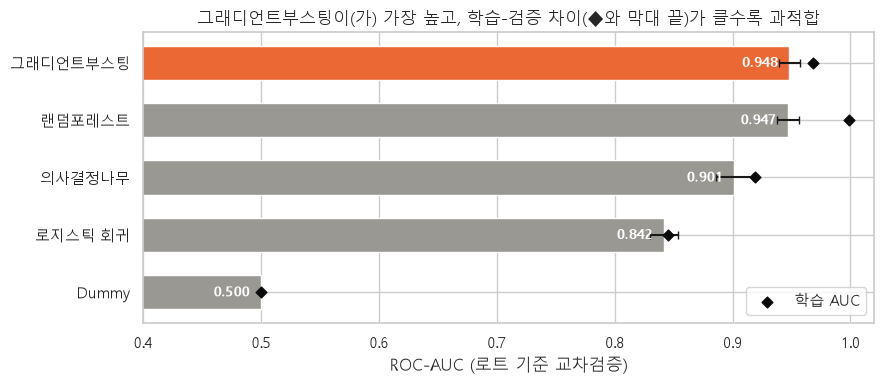

> **이번 실행 결과 해석**
> 막대 끝은 검증 AUC, ◆는 학습 AUC입니다. 오차막대는 폴드 간 표준편차입니다. 이번 실행의 순위를 사용하며 원본의 순위를 가정하지 않습니다.


<a id="chapter-5-topic-104"></a>

### 5-1. 과적합을 눈으로 보기 — 검증 곡선 (Validation Curve)

하이퍼파라미터 하나(나무 깊이)를 바꿔가며 **학습 점수와 검증 점수**를 함께 그리면 과소적합 ↔ 과적합 구간이 보입니다.


**실습 프롬프트 P16**

> **[맥락]** clf_pipe 함수, Xc_tr, yc_tr, g_tr, gkf가 있어.
>
> **[작업]** 의사결정나무의 max_depth를 1~20으로 바꾸며 validation_curve를 그려줘.
> - estimator: clf_pipe(DecisionTreeClassifier(random_state=RANDOM_STATE))
> - param_name='model__max_depth', cv=gkf, groups=g_tr, scoring='roc_auc', n_jobs=-1
> - 학습 평균(검은 선), 검증 평균(주황 선)과 검증 ±1 표준편차 음영.
> - 검증 AUC가 최대인 깊이에 세로 점선과 '최적 깊이 = d' 주석.
>
> **[출력]** 그래프 + 최적 깊이와 그때의 학습/검증 AUC 출력.


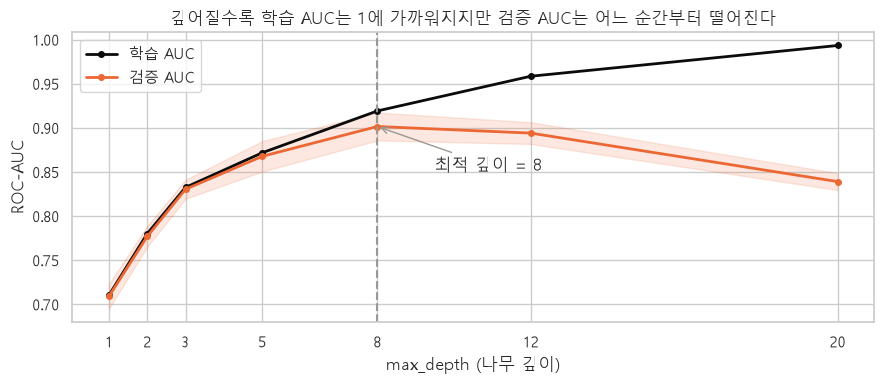

최적 깊이 8: 학습 0.919 / 검증 0.901  |  깊이 20: 학습 0.993 / 검증 0.839


<a id="chapter-5-topic-107"></a>

### 알고리즘 상세 해설 · 검증 곡선 — 깊이가 늘면 무엇이 좋아지고 나빠지는가?

학습 AUC는 모델이 이미 본 자료에 대한 점수이고, 검증 AUC는 같은 폴드에서 보지 않은 로트의 점수입니다.
깊이가 낮아 둘 다 낮으면 과소적합의 단서, 학습만 높고 검증이 낮으면 과적합의 단서입니다.
검증 최고점 주변이 평평하면 한 점의 작은 차이보다 단순성과 폴드 변동을 함께 봅니다.

그림의 음영은 폴드 표준편차 범위입니다. 신뢰구간이나 모든 미래 로트의 성능 보장 범위가 아닙니다.
깊이는 검증에서 선택해야 하며 테스트 점수를 보고 다시 정하지 않습니다.


,깊이,학습 AUC,검증 AUC,검증 SD,학습-검증 간격
0,1,0.7101,0.7088,0.0140,0.0013
1,2,0.7800,0.7768,0.0118,0.0031
2,3,0.8325,0.8304,0.0108,0.0021
3,5,0.8717,0.8677,0.0173,0.0040
4,8,0.9191,0.9014,0.0158,0.0176
5,12,0.9584,0.8940,0.0123,0.0644
6,20,0.9932,0.8390,0.0095,0.1542


이번 후보 중 검증 평균이 가장 높은 깊이는 **8**입니다. 검증 AUC는 **0.9014**, 같은 지점의 학습 AUC는 **0.9191**입니다.

**실행 결과와 그래프 읽기**

이번 데이터·후보·분할에서의 최선 깊이입니다. 항상 깊이가 특정 값에서 최선이라는 법칙이 아니며, 다른 로트 표본에서는 선택이 달라질 수 있습니다.


> **이번 실행 결과 해석**
> 선택 깊이는 위 실행 결과입니다. 학습 점수만 높아지는지, 검증 점수가 함께 오르는지 확인합니다.


**실습 프롬프트 — 로트 단위 학습 곡선**

> 각 그룹 CV 폴드의 검증 로트는 고정하고, 학습 로트를 무작위 순서로 10%, 30%, 60%, 100% 늘려 HGB를 학습해줘.
>
> 학습·검증 AUC와 학습 로트 수를 출력하고 폴드 간 변동을 표시해줘. 테스트 자료는 사용하지 마.


,학습로트,학습행,학습AUC,검증AUC,검증SD
로트 비율,,,,,
0.1000,25.0000,"3,788.0000",0.9994,0.9314,0.0129
0.3000,73.3333,"11,204.6667",0.9866,0.9435,0.0114
0.6000,146.3333,"20,885.6667",0.9758,0.9471,0.0109
1.0000,243.3333,"34,669.3333",0.9679,0.9483,0.0108


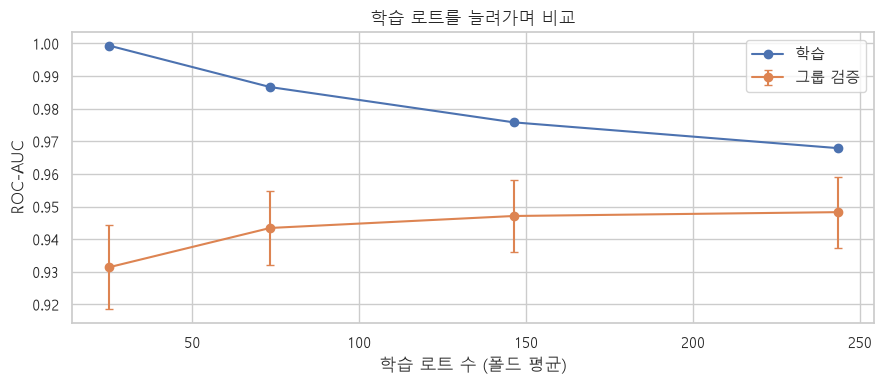

> **이번 실행 결과 해석**
> 로트 수를 늘렸을 때 검증 성능이 얼마나 달라졌는지는 위 곡선에서 확인합니다. 전체 데이터의 순서대로 일부 행만 자르지 않고 로트 단위로 늘렸습니다.


<a id="chapter-5-topic-114"></a>

### 5-2. 하이퍼파라미터 튜닝 — RandomizedSearchCV

가능한 조합을 전부 시험(Grid)하면 오래 걸리므로, **무작위로 일부 조합만** 뽑아 교차검증합니다.

| 하이퍼파라미터 | 뜻 | 크면 |
|---|---|---|
| `learning_rate` | 나무 하나가 오차를 얼마나 고칠지 | 빠르지만 과적합 위험 |
| `max_leaf_nodes` | 나무 하나의 잎 개수 (복잡도) | 복잡한 패턴, 과적합 위험 |
| `min_samples_leaf` | 잎 하나의 최소 표본 수 | 단순해짐 (규제) |
| `l2_regularization` | 가중치 규제 | 단순해짐 (규제) |
| `max_iter` | 나무 개수 (조기 종료 시 최대값) | 더 오래 학습 |


**실습 프롬프트 P18**

> **[맥락]** clf_pipe, Xc_tr, yc_tr, g_tr, gkf가 있어.
>
> **[작업]** 그래디언트부스팅 분류기를 RandomizedSearchCV로 튜닝해줘.
> - 기본 모델: clf_pipe(HistGradientBoostingClassifier(random_state=RANDOM_STATE))
> - 탐색 공간 (Pipeline이므로 'model__' 접두사):
>
>   learning_rate [0.03, 0.05, 0.1, 0.2], max_leaf_nodes [15, 31, 63, 127],
>
>   min_samples_leaf [10, 20, 50, 100], l2_regularization [0, 0.1, 1.0], max_iter [200, 400, 800]
> - n_iter=15, cv=gkf, scoring='roc_auc', random_state=RANDOM_STATE, n_jobs=-1, fit 시 groups=g_tr
> - 테스트 데이터는 절대 사용하지 마.
>
> **[출력]** 최적 파라미터, 최적 CV AUC, 기본 모델 CV AUC(clf_cv 표)와의 차이,
>
>        상위 5개 조합 표(파라미터 + 평균 AUC + 표준편차).


튜닝 소요 21초
최적 파라미터 : {'min_samples_leaf': 50, 'max_leaf_nodes': 127, 'max_iter': 120, 'learning_rate': 0.05, 'l2_regularization': 0.1}
최적 CV AUC  : 0.9502  (기본값 0.9483, 차이 +0.0019)


,min_samples_leaf,max_leaf_nodes,max_iter,learning_rate,l2_regularization,mean_test_score,std_test_score
2,50,127,120,0.0500,0.1000,0.9502,0.0080
3,50,63,80,0.1000,0.0000,0.9494,0.0081
0,50,31,80,0.1000,0.0000,0.9480,0.0087
1,100,15,80,0.0500,1.0000,0.9399,0.0099


<a id="chapter-5-topic-117"></a>

### 알고리즘 상세 해설 · 튜닝 — 후보 설정을 검증 데이터로 비교하기

`model__max_iter`에서 두 밑줄 앞은 Pipeline 단계 이름, 뒤는 모델 파라미터입니다.
RandomizedSearchCV는 후보 조합을 선택하고 각 조합의 CV 평균으로 순위를 정한 뒤 최선 설정을 전체 학습 자료에 다시 fit합니다.
탐색 최고 점수는 여러 후보 중 최고를 고른 수치이므로 선택 편향을 포함합니다. 최종 테스트 점수와 구분합니다.

이 교재의 HGB 튜닝은 원본 학습 흐름을 유지한 알고리즘 사례입니다. 모델군 전체를 자동으로 최종 선택하는 절차는 아니며, 다른 모델의 CV가 더 높다면 그 사실도 보고합니다.
새로운 탐색은 학습 영역에서만 수행하고, 테스트 결과를 보고 후보를 추가하지 않습니다.


,params,mean_test_score,std_test_score,mean_fit_time
2,"{'model__min_samples_leaf': 50, 'model__max_le...",0.9502,0.0080,2.9702
3,"{'model__min_samples_leaf': 50, 'model__max_le...",0.9494,0.0081,1.1814
0,"{'model__min_samples_leaf': 50, 'model__max_le...",0.9480,0.0087,0.7477
1,"{'model__min_samples_leaf': 100, 'model__max_l...",0.9399,0.0099,0.6393


실제 탐색 조합 수: 4 폴드 수: 3
후보 검증 fit 수: 12 + 최선 설정 전체 학습 1회


최선 HGB 검증 AUC **0.9502**. 기본 HGB 대비 **+0.0019**입니다. 개선이 음수일 수도 있습니다.

**실행 결과와 그래프 읽기**

점수 차이가 작으면 폴드별 변동과 시간도 봅니다. 후보 수를 늘린다고 반드시 실제 일반화가 좋아지는 것은 아닙니다. 최선 설정과 random_state를 함께 기록해야 재현할 수 있습니다.


> **이번 실행 결과 해석**
> 튜닝 결과는 탐색한 후보 중 최선입니다. 더 넓은 설정 전체의 전역 최적값이 아니며, 기본 모델보다 반드시 좋아지지는 않습니다.


<a id="chapter-5-topic-121"></a>

### 5-3. 임계값 정하기 — 0.5는 정답이 아니다

모델은 확률을 내고, **사람이 정한 임계값**으로 REAL/FALSE를 나눕니다. 4-3에서 정한 기준은
> **"진성결함 재현율 98% 이상을 지키면서, 가성결함을 최대한 많이 걸러낸다(특이도 최대)."**

임계값도 '튜닝'이므로 **테스트가 아닌 학습 데이터의 교차검증 예측(Out-of-Fold)** 으로 정합니다.


**실습 프롬프트 P22**

> **[맥락]** best_clf(튜닝된 Pipeline), Xc_tr, yc_tr, g_tr, gkf가 있어.
>
> **[작업]**
> 1. cross_val_predict(best_clf, Xc_tr, yc_tr, groups=g_tr, cv=gkf, method='predict_proba', n_jobs=-1)로
>
>    학습 데이터의 OOF 확률 oof를 구해줘 (각 행은 자기가 검증 fold일 때 예측됨).
> 2. 임계값 0.01~0.99(0.01 간격)마다 재현율(REAL), 정밀도, 특이도(FALSE)를 계산해 thr_tbl로.
> 3. 재현율 ≥ 0.98을 만족하는 임계값 중 가장 큰 값(=특이도 최대)을 THR로 정해줘.
> 4. 세 지표를 임계값에 따라 선 그래프로 그리고(재현율 주황, 특이도 파랑, 정밀도 회색),
>
>    0.98 수평 점선과 THR 세로 점선, 0.5 세로 점선(회색)을 표시해줘.
>
> **[출력]** 그래프 + THR, 그때의 재현율·특이도·정밀도 출력.


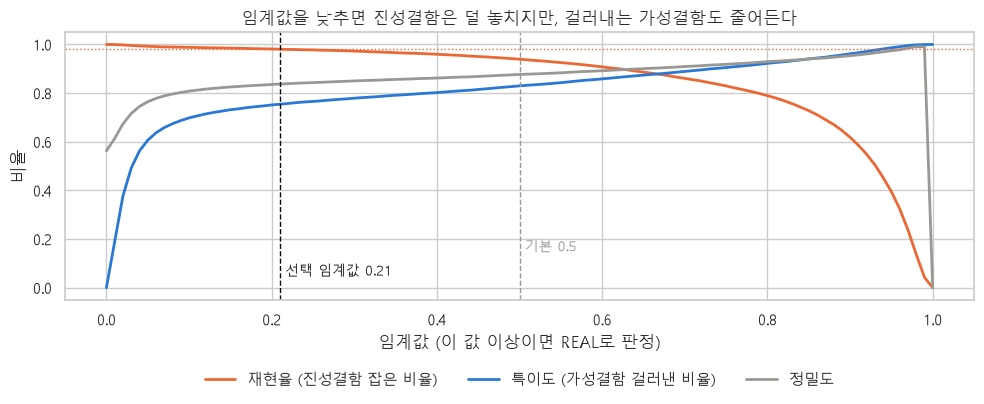

선택 임계값 THR = 0.21


,재현율,정밀도,특이도
임계값,,,
0.2100,0.9805,0.8371,0.7544
0.5000,0.9395,0.8767,0.8298


<a id="chapter-5-topic-124"></a>

### 알고리즘 상세 해설 · 임계값 — 확률 모델과 리뷰 규칙을 분리하기

OOF 확률은 각 행을 학습에 사용하지 않은 폴드 모델이 만든 확률입니다. 학습 행 자체에 fit한 모델의 확률로 임계값을 정하면 낙관적일 수 있습니다.
여기서는 OOF에서 목표 재현율 98% 이상인 후보 중 가장 큰 임계값을 택하고, **테스트를 보기 전에 고정**합니다.
같은 CV에서 설정을 튜닝한 뒤 OOF를 구했으므로 완전히 독립적인 성능 추정은 아닙니다. 더 엄격한 설계에는 별도 임계값 검증 세트나 중첩 CV가 필요합니다.

임계값을 낮추면 REAL 판정이 늘어 FN은 줄고 FP는 늘거나 유지됩니다. 리뷰 생략 비율은 모든 후보 중 FALSE 판정 비율입니다.
전체 비용은 FN의 손실·리뷰 비용·작업 시간에 따라 다르므로 같은 건수 감소가 같은 공수 절감을 보장하지 않습니다.
목표 재현율은 OOF에서의 선택 기준이지 테스트나 운영에서의 98% 보장이 아닙니다.


,임계값,재현율,놓친 REAL,리뷰 생략 비율
0,0.0000,1.0000,0,0.0000
1,0.2100,0.9805,571,0.3407
2,0.5000,0.9395,1772,0.3968
3,1.0000,0.0000,29272,1.0000


테스트 평가 전에 고정한 임계값: 0.21


**실행 결과와 그래프 읽기**

임계값 0은 모두 리뷰하는 규칙이라 놓친 REAL이 0이고 생략도 0입니다. 선택 임계값은 비용과 목표 사이의 하나의 정책이며 모든 상황의 정답은 아닙니다.


> **이번 실행 결과 해석**
> OOF 목표를 만족하는 임계값을 선택했습니다. 새 로트에서 목표 재현율을 유지하는지는 이후 고정 테스트로 평가합니다.


<a id="chapter-5-topic-128"></a>

### 5-4. 테스트 데이터로 최종 평가 (단 한 번)

지금까지 테스트 데이터는 한 번도 쓰지 않았습니다. 이제 **튜닝된 모델을 학습 데이터 전체로 다시 학습**하고 테스트에서 평가합니다.
비교를 위해 로지스틱 회귀와 랜덤포레스트도 함께 평가합니다.


**실습 프롬프트 P19**

> **[맥락]** search_clf.best_estimator_(튜닝된 HGB, 이미 학습 데이터 전체로 재학습됨), clf_models,
>
>        Xc_tr, yc_tr, Xc_te, yc_te가 있어.
>
> **[작업]**
> 1. best_clf = search_clf.best_estimator_ 로 두고, '로지스틱 회귀', '랜덤포레스트', 'Dummy'는 학습 데이터로 fit.
> 2. 4개 모델의 테스트 예측 확률(1열)을 딕셔너리 proba_te에 저장.
> 3. 임계값 0.5 기준으로 AUC, PR-AUC, 정확도, 정밀도, 재현율, 특이도, F1을 계산해 표로.
>
> **[조건]** 지표 계산을 함수 clf_report(y, proba, thr=0.5)로 만들어 재사용할 수 있게 해줘.
>
> **[출력]** AUC 내림차순 표, 소수점 4자리.


,AUC,AP,정확도,정밀도,재현율(REAL),특이도(FALSE),F1
그래디언트부스팅(튜닝),0.9549,0.9557,0.9008,0.8783,0.9524,0.8371,0.9138
랜덤포레스트,0.9502,0.9474,0.9008,0.8765,0.9550,0.8339,0.9141
로지스틱 회귀,0.8393,0.8297,0.7646,0.7432,0.8768,0.6261,0.8045
Dummy,0.5000,0.5524,0.5524,0.5524,1.0000,0.0000,0.7117


> **이번 실행 결과 해석**
> 위 표는 사전에 지정한 모델들의 테스트 결과입니다. 테스트 순위에 따라 추가 튜닝하지 않습니다. 최종 사용 모델은 학습 단계에서 정한 HGB 사례이며 CV가 다른 모델을 지지한다면 함께 보고합니다.


**실습 프롬프트 P20**

> **[맥락]** yc_te, proba_te['그래디언트부스팅(튜닝)']가 있어.
>
> **[작업]** 임계값 0.5의 혼동행렬을 1×2로 그려줘.
> - 왼쪽: 개수(정수), 오른쪽: 실제 행 기준 비율(%) — 각 행의 합이 100%
> - seaborn heatmap, 색은 Blues, 축 라벨은 'FALSE(가성)', 'REAL(진성)', x=예측, y=실제
> - 칸 위에 TN/FP/FN/TP 이름이 함께 보이도록 주석을 만들어줘 (예: 'TN\n5,123').
>
> **[출력]** 그래프 + 놓친 진성결함(FN) 수 한 줄.


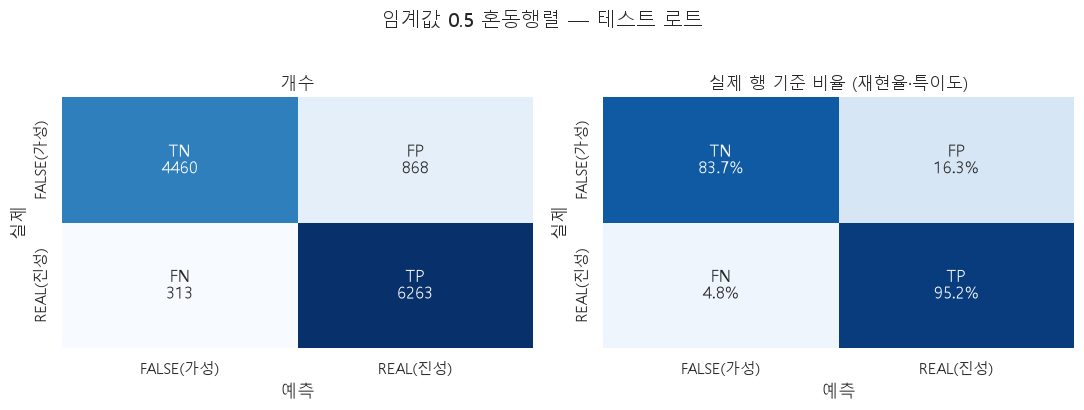

놓친 진성결함(FN) : 313개 / 진성결함 6,576개 중


**실습 프롬프트 P21**

> **[맥락]** yc_te와 proba_te(모델 4개의 테스트 예측 확률)가 있어.
>
> **[작업]** ROC 곡선과 PR 곡선을 1×2로 그려줘.
> - 모델 색 고정: 그래디언트부스팅(튜닝)=주황 C_REAL, 랜덤포레스트=초록 '#1baf7a',
>
>   로지스틱 회귀=파랑 C_FALSE, Dummy=회색 점선.
> - 범례에 모델명과 AUC(왼쪽) / AP(오른쪽) 값.
> - ROC 왼쪽에 대각선(무작위) 회색 점선, PR 오른쪽에 REAL 비율 수평선(기준선).
> - 선 두께 2.


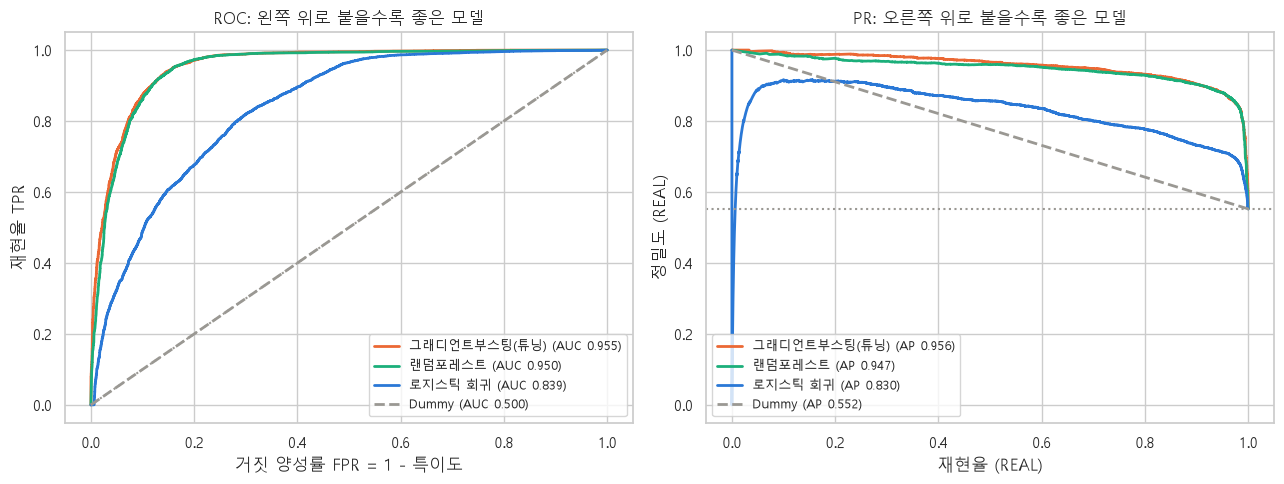

> **이번 실행 결과 해석**
> ROC 곡선과 PR 곡선의 의미를 구분합니다. AP는 재현율 증가량으로 정밀도를 가중한 요약이며 사다리꼴 PR 면적과 항상 같지 않습니다.


,임계값 0.5,임계값 0.21
AUC,0.9549,0.9549
AP,0.9557,0.9557
정확도,0.9008,0.8859
정밀도,0.8783,0.8387
재현율(REAL),0.9524,0.9825
특이도(FALSE),0.8371,0.7667
F1,0.9138,0.9049


테스트 결함 총 11,904개
· 리뷰 생략(FALSE 판정) : 4,200개 (35.3%)  → 리뷰 건수 기준 생략 비율 35.3% (실제 시간 절감은 별도 측정)
· 그중 실제 진성결함    : 115개 (전체 진성결함의 1.7%)
· 엔지니어 리뷰 대상    : 7,704개


> **이번 실행 결과 해석**
> 리뷰 생략 건수 안에는 놓친 REAL도 포함됩니다. 건수 감소와 실제 시간·비용 절감을 구분하고 출력된 FN을 함께 보고합니다.


**실습 프롬프트 P24**

> **[맥락]** te(테스트 원본 DataFrame: Step_desc, Class 포함), yc_te, p_best(테스트 확률), THR가 있어.
>
> **[작업]** 오차 분석을 해줘.
> 1. 공정(Step_desc)별: 결함 수, REAL 비율, AUC, THR 기준 재현율·특이도 표 (STEP_ORDER 순서).
> 2. 실제 Class별: 결함 수, THR 기준 '틀린 비율(%)' 표 — 결함 수 30개 이상 Class만, 틀린 비율 내림차순.
>
> **[출력]** 표 2개 + 어떤 공정·Class에서 모델이 약한지 해석.


,결함 수,REAL 비율,AUC,재현율,특이도
Step_desc,,,,,
PC,"1,372.0000",0.2680,0.9930,0.9810,0.9250
RMG,"4,438.0000",0.5030,0.9490,0.9740,0.7460
CBCMP,"6,094.0000",0.6530,0.9360,0.9880,0.7130


C:\Users\ryp16\AppData\Local\Temp\ipykernel_23680\4213153862.py:12: UserWarning: numexpr version '2.14.1' can silently return incorrect results and will not be used by pandas. Install numexpr 2.14.2 or newer to re-enable numexpr acceleration.
  by_class.query("결함수 >= 30").sort_values("틀린비율(%)", ascending=False).round(1)


,결함수,실제,틀린비율(%)
Class,,,
9,5328,FALSE,23.3000
10,923,REAL,6.1000
17,90,REAL,3.3000
99,960,REAL,3.2000
14,62,REAL,3.2000
28,137,REAL,1.5000
56,342,REAL,0.9000
21,2998,REAL,0.6000
20,392,REAL,0.0000


> **이번 실행 결과 해석**
> 공정·Class별 오류율은 위 표의 n과 함께 읽습니다. 작은 집단의 높은 오류율만으로 특정 원인을 확정하지 않습니다.


---

<a id="chapter-6"></a>

## 6장. 회귀 모델링 — 신호로 결함 크기 추정

> **이 장의 목표**
> - 로그 변환 타깃으로 회귀 모델을 학습하고 원래 단위로 평가한다.
> - 교차검증으로 회귀 모델을 비교·튜닝한다.
> - 예측-실제 그래프와 잔차로 모델의 약점을 찾는다.

[전체 목차](#contents) · [이전 장](#chapter-5) · [다음 장](#chapter-7)

**이 장의 개념과 실습**

- [6-1. 회귀 모델 구성과 교차검증](#chapter-6-topic-143)
- [6-2. 회귀 모델 하이퍼파라미터 튜닝](#chapter-6-topic-152)
- [6-3. 테스트 데이터로 회귀 성능 평가](#chapter-6-topic-156)
- [6-4. 예측값과 잔차 진단](#chapter-6-topic-159)
- [6-5. 공정·크기 구간별 오차 분석](#chapter-6-topic-166)

**알고리즘 상세 해설 바로가기**

- [로그 타깃 회귀 — 어떤 오차를 줄이는가?](#chapter-6-topic-146)
- [회귀나무와 숲의 외삽 한계·잔차 읽기](#chapter-6-topic-162)


<a id="chapter-6-topic-143"></a>

### 6-1. 회귀 모델 구성과 교차검증


**실습 프롬프트 P25**

> **[맥락]** make_prep, FEAT_REG(크기 변수 제외), Xr_tr, yr_tr(log10 SIZE_D), g_tr, gkf, cv_compare 함수가 있어.
>
> **[작업]**
> 1. 원래 단위(µm) 평가용 지표 함수 2개를 만들어줘 (입력은 log10 값):
>
>    mae_um(y, p) = MAE(10**y, 10**p),  mdape(y, p) = 중앙값(|10**p − 10**y| / 10**y) × 100
> 2. SCORING_REG = {'R2': 'r2', 'MAE_um': make_scorer(mae_um, greater_is_better=False),
>
>                   'MdAPE': make_scorer(mdape, greater_is_better=False)}
> 3. 회귀 모델 6개 Pipeline 딕셔너리 reg_models (함수 reg_pipe(model, scale)):
>
>    'Dummy'(DummyRegressor mean), '선형 회귀'(scale=True), '릿지'(Ridge(alpha=10), scale=True),
>
>    '의사결정나무'(max_depth=10), '랜덤포레스트'(n_estimators=150, min_samples_leaf=3, max_features=0.5, n_jobs=-1),
>
>    '그래디언트부스팅'(HistGradientBoostingRegressor) — 트리는 random_state=RANDOM_STATE
> 4. cv_compare(reg_models, Xr_tr, yr_tr, g_tr, SCORING_REG, main='R2')로 비교, R2 내림차순.
>
> **[출력]** 표 (소수점 4자리).


교차검증 소요 44초


,R2,MAE_um,MdAPE,R2_표준편차,R2_학습,과적합 간격,학습시간(초)
랜덤포레스트,0.8135,0.1569,16.8436,0.0040,0.9423,0.1288,11.8299
그래디언트부스팅,0.8052,0.1598,18.3237,0.0058,0.8480,0.0428,0.8455
의사결정나무,0.7016,0.1986,21.0480,0.0091,0.8129,0.1112,0.4208
릿지,0.4817,0.3115,37.2140,0.0091,0.4848,0.0031,0.0633
선형 회귀,0.4817,0.3117,37.1996,0.0092,0.4848,0.0031,0.0741
Dummy,-0.0006,0.2879,51.7235,0.0004,0.0000,0.0006,0.0381


<a id="chapter-6-topic-146"></a>

### 알고리즘 상세 해설 · 로그 타깃 회귀 — 어떤 오차를 줄이는가?

이 회귀는 $z=\log_{10}(SIZE_D)$를 예측합니다. 학습에서 로그 오차를 줄이는 것은 원단위의 동일한 µm 오차를 줄이는 것과 다릅니다.
0.1→0.2µm와 1→2µm는 모두 두 배이고 로그 차이는 약 0.301입니다. 원단위 절대오차는 각각 0.1·1µm로 다릅니다.
따라서 로그 R²와 원단위 MAE·RMSE를 함께 보고합니다. 로그 R²를 “크기 변동의 몇 %”라고 원단위로 해석하지 않습니다.

역변환 $10^{\hat z}$는 일반적으로 원단위 조건부 평균과 같지 않습니다. 잔차 분포에 따라 역변환 편향이 있습니다.
DummyRegressor(mean)는 여기서 **로그 평균**을 예측하므로 역변환하면 기하평균입니다. 원단위 산술평균 기준 모델과 다릅니다.


,실제 µm,예측 µm,절대오차 µm,로그오차
0,0.1000,0.2000,0.1000,0.3010
1,1.0000,2.0000,1.0000,0.3010
2,10.0000,20.0000,10.0000,0.3010


학습 크기 산술평균=0.4051 µm, 로그평균 역변환=0.2098 µm


**실행 결과와 그래프 읽기**

세 행의 로그오차는 같고 원단위 오차는 10배씩 증가합니다. 큰 결함의 절대오차를 중시한다면 현재 학습 목적이 그 비용과 맞는지 별도로 검토해야 합니다.


**실습 프롬프트 P26**

> **[맥락]** reg_cv 표(모델별 R2, MAE_um, MdAPE)가 있어.
>
> **[작업]** 회귀 모델 비교를 1×3 가로 막대그래프로 그려줘 (R2 / MAE(µm) / MdAPE(%)).
> - 각 패널에서 가장 좋은 모델만 주황(C_REAL), 나머지 회색. (R2는 클수록, 나머지는 작을수록 좋음)
> - 막대 끝에 값 표시, Dummy의 값은 회색 점선 세로선으로 표시(기준선).
> - 패널 제목에 '↑ 클수록 좋음' / '↓ 작을수록 좋음'.


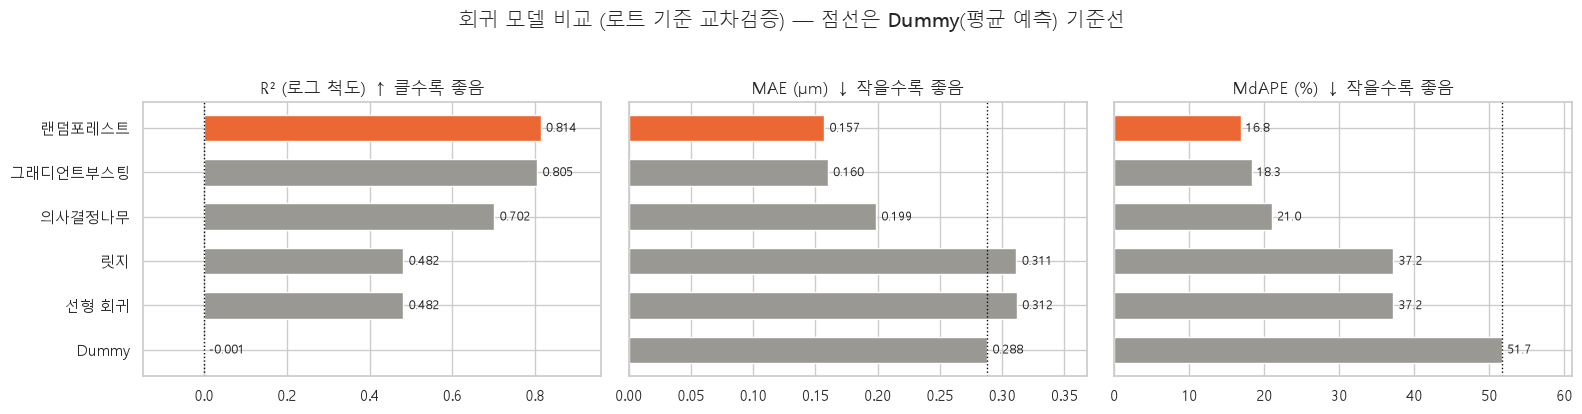

> **이번 실행 결과 해석**
> 회귀 성능은 위 표의 실제 계산값으로 비교합니다. R²는 로그 척도이며 음수를 유지했습니다. 원단위 MAE와 최선 모델이 다를 수 있습니다.


<a id="chapter-6-topic-152"></a>

### 6-2. 회귀 모델 하이퍼파라미터 튜닝


**실습 프롬프트 P27**

> **[맥락]** reg_pipe, Xr_tr, yr_tr, g_tr, gkf가 있어.
>
> **[작업]** HistGradientBoostingRegressor를 RandomizedSearchCV로 튜닝해줘.
> - 탐색 공간: learning_rate [0.03, 0.05, 0.1, 0.2], max_leaf_nodes [15, 31, 63, 127],
>
>   min_samples_leaf [10, 20, 50, 100], l2_regularization [0, 0.1, 1.0], max_iter [200, 400, 800]
> - n_iter=15, cv=gkf, scoring='r2', random_state=RANDOM_STATE, n_jobs=-1, groups=g_tr
>
> **[출력]** 최적 파라미터, 최적 CV R², 기본 모델 대비 차이.


튜닝 소요 16초
최적 파라미터 : {'min_samples_leaf': 50, 'max_leaf_nodes': 127, 'max_iter': 120, 'learning_rate': 0.05, 'l2_regularization': 0.1}
최적 CV R²   : 0.8160  (기본값 0.8052, 차이 +0.0108)


> **이번 실행 결과 해석**
> 회귀 튜닝은 로그 R² 기준으로 설정을 골랐습니다. 원단위 MAE 최적화를 뜻하지 않습니다.


<a id="chapter-6-topic-156"></a>

### 6-3. 테스트 데이터로 회귀 성능 평가


,R²(로그),MAE(µm),RMSE(µm),MdAPE(%)
그래디언트부스팅(튜닝),0.8140,0.1250,0.8857,17.4887
랜덤포레스트,0.8127,0.1243,0.9246,17.0736
선형 회귀,0.4806,0.3023,3.0721,39.4676
Dummy,-0.0030,0.2530,1.1866,54.7795


Dummy 대비 MAE 51% 감소


> **이번 실행 결과 해석**
> Dummy 대비 MAE 변화는 위 출력값입니다. 여기의 Dummy는 로그 평균 예측이므로 원단위 기하평균 기준임에 유의합니다.


<a id="chapter-6-topic-159"></a>

### 6-4. 예측값과 잔차 진단


**실습 프롬프트 P29**

> **[맥락]** yr_te(실제 log10 크기), pred_te['그래디언트부스팅(튜닝)']가 있어.
>
> **[작업]** 회귀 진단 그래프 1×2를 그려줘.
> 1. 왼쪽: 실제 SIZE_D vs 예측 SIZE_D (µm, 둘 다 로그 축) hexbin(gridsize=60, cmap='Blues', bins='log'),
>
>    y=x 대각선(검은 점선), ±2배 오차 띠(회색 점선 y=2x, y=x/2). 제목에 '±2배 안에 든 비율 xx%'.
> 2. 오른쪽: 잔차(실제 log − 예측 log) vs 예측 log 산점도(점 작게, 투명도 0.15),
>
>    y=0 선, 예측값 구간(20개 분위)별 잔차 중앙값을 주황 선으로.
>
> **[조건]** 로그 축은 plain_log로 일반 숫자 눈금.


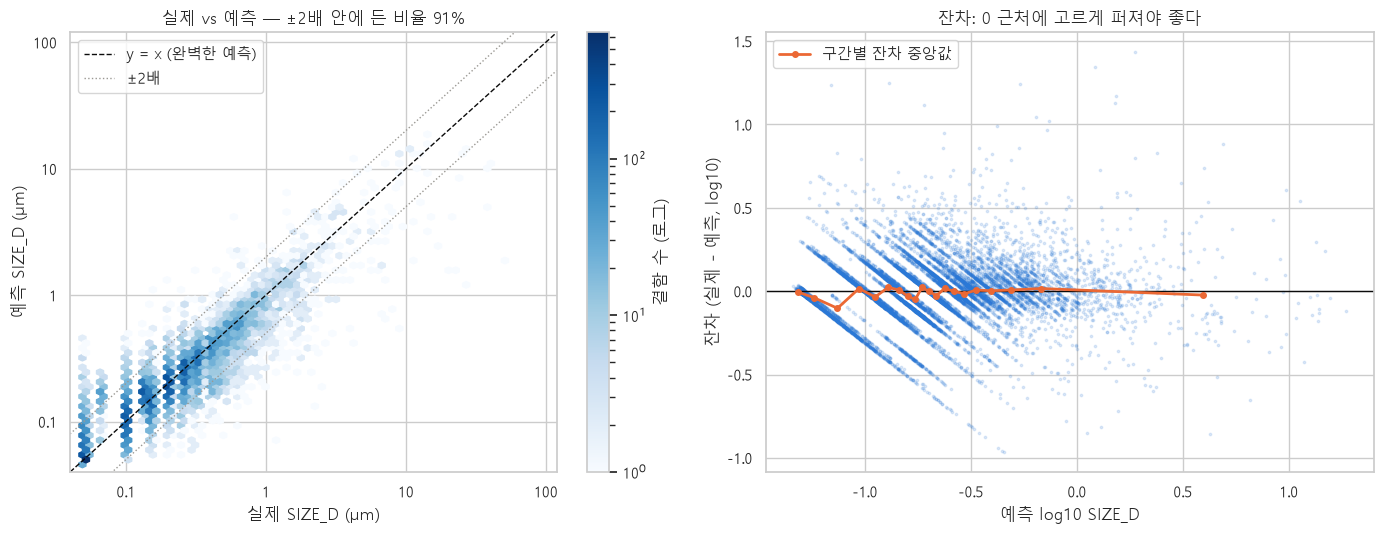

<a id="chapter-6-topic-162"></a>

### 알고리즘 상세 해설 · 회귀나무와 숲의 외삽 한계·잔차 읽기

기본 제곱오차 회귀나무는 리프 안 학습 타깃 평균을 반환합니다. 랜덤포레스트도 그런 평균의 평균이라 학습 타깃 범위를 벗어난 외삽에 제한이 있습니다.
HGB는 보정 나무의 합이므로 동일한 범위 제한이라고 단정할 수는 없지만, 학습에서 드문 큰 값에서 잘 맞는지는 별도 확인해야 합니다.

실제−예측 잔차가 양수면 과소예측, 음수면 과대예측입니다. 잔차 패턴이 있으면 모델이 놓친 구조의 단서입니다.
잔차가 정규분포여야 모든 머신러닝 모델의 예측이 유효한 것은 아닙니다.
그림의 ±2배는 예측구간이 아니라 오차를 요약하는 허용 띠입니다.


,n,MAE,실제중앙값,예측중앙값
구간,,,,
1 µm 미만,11390,0.0615,0.1990,0.1867
1 µm 이상,514,1.5333,1.6400,1.3177


원단위 R²: 0.43347789389748914 로그 R²: 0.8140247050419467


**실행 결과와 그래프 읽기**

전체 평균이 좋아도 큰 결함 구간에서 MAE가 클 수 있습니다. 두 구간의 n도 함께 읽습니다. 테스트에서 발견한 문제로 모델을 수정한다면 다음 버전에는 새로운 최종 평가 자료가 필요합니다.


> **이번 실행 결과 해석**
> 대각선 아래 점은 크기를 작게 예측한 경우입니다. 잔차 실제−예측의 부호와 표시 범위를 확인합니다.


<a id="chapter-6-topic-166"></a>

### 6-5. 공정·크기 구간별 오차 분석


**실습 프롬프트 P30**

> **[맥락]** te(테스트 원본, Step_desc·SIZE_D 포함), yr_te, pred_te['그래디언트부스팅(튜닝)']가 있어.
>
> **[작업]** 회귀 오차를 두 가지로 쪼개 분석해줘.
> 1. 실제 크기 등급별: SIZE_D를 [0, 0.1), [0.1, 0.2), [0.2, 0.5), [0.5, 1), [1, ∞) µm로 나누고
>
>    등급별 결함 수, MAE(µm), MdAPE(%), 평균 잔차(log, +면 과소예측) 표.
> 2. 크기 등급을 '소(<0.2) / 중(0.2~1) / 대(≥1)' 3단계로 나눠, 실제 등급과 예측 등급의
>
>    교차표(행 기준 %)를 만들어 등급 일치율을 계산해줘.
>
> **[출력]** 표 2개 + 일치율 한 줄.


,결함 수,MAE(µm),MdAPE(%),평균 잔차(log)
크기구간,,,,
<0.1,"3,051.0000",0.0270,17.6760,-0.0970
0.1~0.2,"3,687.0000",0.0380,17.1200,-0.0240
0.2~0.5,"3,519.0000",0.0740,15.5730,0.0520
0.5~1,"1,133.0000",0.1910,20.5150,0.0820
≥1,514.0000,1.5330,34.9670,0.1650


예측 등급,소(<0.2),중(0.2~1),대(≥1)
실제 등급,,,
소(<0.2),83.9000,16.1000,0.0000
중(0.2~1),12.4000,86.0000,1.6000
대(≥1),0.6000,32.1000,67.3000


크기 등급 일치율 : 84.0%


> **이번 실행 결과 해석**
> 구간별 MAE·상대오차·n을 같이 읽습니다. 크기 등급 경계는 이 실습의 교육용 설정이며 공식 제조 규격이 아닙니다.


---

<a id="chapter-7"></a>

## 7장. 변수 중요도 — 모델은 무엇을 보고 판단했나?

> **이 장의 목표**
> - 변수 중요도의 종류(계수·불순도·순열·그룹·PDP)와 장단점을 안다.
> - 여러 방법의 결과를 비교해 믿을 만한 결론을 낸다.
> - 중요도 ≠ 인과관계임을 이해한다.

[전체 목차](#contents) · [이전 장](#chapter-6) · [다음 장](#chapter-8)

**이 장의 개념과 실습**

- [7-1. 변수 중요도의 종류](#chapter-7-topic-171)
- [7-2. 회귀 모델의 변수 중요도](#chapter-7-topic-196)

**알고리즘 상세 해설 바로가기**

- [선형 계수 — 확률 증가량과 오즈비를 구분하기](#chapter-7-topic-174)
- [변수 중요도 — 무엇을 섞었고 무엇을 측정했나?](#chapter-7-topic-186)
- [PDP·ICE — 입력을 바꾸어 모델의 반응 관찰하기](#chapter-7-topic-201)


<a id="chapter-7-topic-171"></a>

### 7-1. 변수 중요도의 종류

| 방법 | 원리 | 장점 | 주의 |
|---|---|---|---|
| **표준화 계수** (선형 모델) | 표준화된 특성의 계수 크기·부호 | 방향(+/−)까지 보임 | 비선형 관계는 못 잡음 |
| **불순도 감소 (MDI)** (트리) | 분할로 불순도를 얼마나 줄였나 | 학습 중 공짜로 계산 | 학습 데이터 기준, **값 종류가 많은 변수를 과대평가** |
| **순열 중요도** (모든 모델) | 한 변수를 무작위로 섞었을 때 성능이 얼마나 떨어지나 | 모델 무관, 테스트 데이터로 계산 가능 | **상관 높은 변수끼리 중요도를 나눠 가짐** |
| **그룹 순열 중요도** | 관련 변수 묶음을 한꺼번에 섞음 | 상관 문제 완화 | 그룹 정의가 필요 |
| **부분 의존도 (PDP)** | 한 변수만 바꿀 때 평균 예측이 어떻게 변하나 | **방향과 모양**을 보여줌 | 변수 간 상호작용은 평균에 묻힘 |

```
 순열 중요도의 원리
   원래 테스트 데이터 → AUC 0.95
   INTENSITY 열만 무작위로 섞음 → AUC 0.80   ⇒ 중요도 = 0.95 − 0.80 = 0.15
   ANGLE 열만 섞음            → AUC 0.95   ⇒ 중요도 ≈ 0      (안 쓰는 변수)
```

> **중요도 ≠ 원인.** "모델이 예측에 많이 쓴 변수"일 뿐, 그 변수를 바꾸면 결함이 바뀐다는 뜻이 아닙니다.


**실습 프롬프트 P31**

> **[맥락]** final_clf['로지스틱 회귀'](학습된 Pipeline, prep에 StandardScaler + OneHot)가 있어.
>
> **[작업]** 로지스틱 회귀의 표준화 계수를 변수 중요도로 보여줘.
> 1. named_steps['prep'].get_feature_names_out()과 named_steps['model'].coef_[0]으로 Series coef를 만들어줘.
> 2. 절댓값 기준 상위 15개를 가로 막대로: 양수(REAL 쪽)=주황 C_REAL, 음수(FALSE 쪽)=파랑 C_FALSE.
> 3. 오즈비 exp(계수)도 계산해 '1 표준편차 증가 시 REAL 오즈 x배' 표로 상위 5개.
>
> **[조건]** 0에 세로선, 제목에 해석 방향을 써줘.


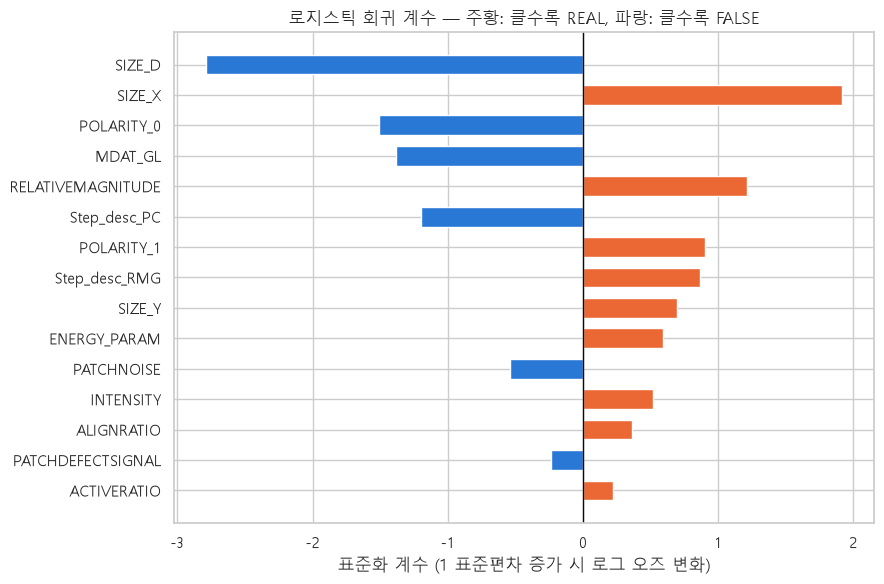

,계수,오즈비 exp(계수)
SIZE_D,-2.7880,0.0620
SIZE_X,1.9180,6.8080
POLARITY_0,-1.5100,0.2210
MDAT_GL,-1.3860,0.2500
RELATIVEMAGNITUDE,1.2120,3.3600


<a id="chapter-7-topic-174"></a>

### 알고리즘 상세 해설 · 선형 계수 — 확률 증가량과 오즈비를 구분하기

수치형 계수 β는 다른 입력을 고정할 때 표준화 입력이 1 증가하는 로그 오즈 변화입니다. 따라서 오즈비는 exp(β)입니다.
범주 원-핫 계수는 1 SD가 아니라 상태 변화에 대응합니다. 모든 범주 열을 유지했다면 두 범주 비교는 계수 차이로 봐야 합니다.
상관된 입력이 많으면 계수의 부호와 크기가 불안정할 수 있습니다. 계수 크기가 인과적 영향력은 아닙니다.


,기존 확률,같은 β 적용 후 확률,확률 차이(%p),오즈비
0,0.1000,0.1828,8.2840,2.0138
1,0.5000,0.6682,16.8188,2.0138
2,0.9000,0.9477,4.7709,2.0138


**실행 결과와 그래프 읽기**

동일한 오즈비를 곱해도 시작 확률에 따라 %p 변화가 다릅니다. 실제 계수 표에서는 입력 변환과 기준 상태를 먼저 확인합니다.


**실습 프롬프트 P32**

> **[맥락]** final_clf['랜덤포레스트'](학습된 Pipeline), CAT_COLS가 있어.
>
> **[작업]** 랜덤포레스트의 불순도 기반 중요도(feature_importances_)를 원래 변수 단위로 보여줘.
> 1. 원-핫 열(예: Step_desc_PC, POLARITY_1)은 원래 변수(Step_desc, POLARITY)로 합산해줘 → Series mdi.
> 2. 내림차순 가로 막대(단일 색 C_GRAY, 상위 3개만 C_REAL), 막대 끝에 값(소수 3자리).


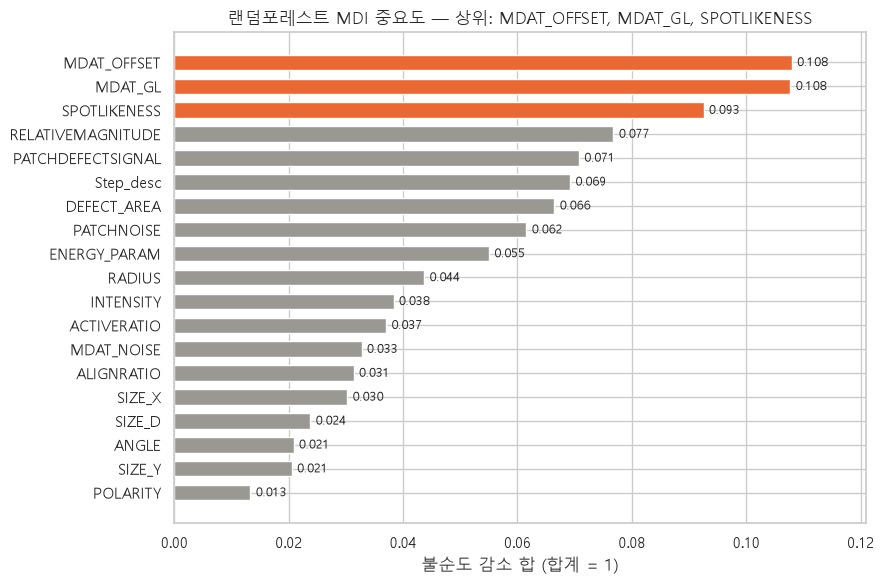

**실습 프롬프트 P33**

> **[맥락]** best_clf(튜닝된 HGB Pipeline), Xc_te, yc_te가 있어.
>
> **[작업]** 테스트 데이터로 순열 중요도를 계산해줘.
> - permutation_importance(best_clf, Xc_te, yc_te, scoring='roc_auc', n_repeats=10,
>
>   random_state=RANDOM_STATE, n_jobs=-1) — Pipeline에 원본 열을 넣으므로 결과도 원래 변수 단위.
> - 결과를 DataFrame perm_clf(평균, 표준편차)로, 평균 내림차순.
> - 가로 막대 + 오차막대(표준편차), 상위 3개 C_REAL, 나머지 C_GRAY, 0에 세로선.
>
> **[출력]** 그래프 + '상위 5개 변수가 전체 중요도 합의 xx%' 한 줄.


계산 6초


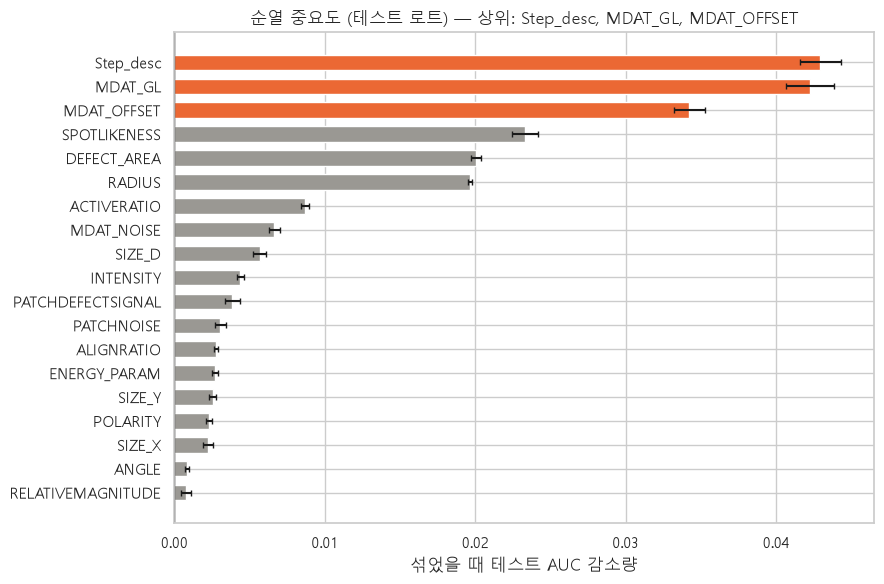

상위 5개 변수가 전체 중요도 합의 71%


> **이번 실행 결과 해석**
> 순열 중요도는 고정 모델의 테스트 점수 감소입니다. 값이 작거나 음수인 변수를 바로 제거하지 않습니다.


,로지스틱 |계수|,RF 불순도,HGB 순열,평균 순위
MDAT_GL,5,2,2,3.0000
Step_desc,3,6,1,3.3333
MDAT_OFFSET,16,1,3,6.6667
SPOTLIKENESS,15,3,4,7.3333
SIZE_D,1,16,9,8.6667
PATCHDEFECTSIGNAL,12,5,11,9.3333
PATCHNOISE,9,8,12,9.6667
DEFECT_AREA,17,7,5,9.6667
RELATIVEMAGNITUDE,6,4,19,9.6667
ENERGY_PARAM,8,9,14,10.3333


방법 간 순위 일치도 (스피어만 ρ)


,로지스틱 |계수|,RF 불순도,HGB 순열
로지스틱 |계수|,1.0000,-0.2100,-0.2100
RF 불순도,-0.2100,1.0000,0.5800
HGB 순열,-0.2100,0.5800,1.0000


> **이번 실행 결과 해석**
> 서로 다른 모델과 척도의 중요도 순위를 비교한 참고 표입니다. 순위 평균이 객관적인 최종 인과 중요도를 뜻하지 않습니다.


**실습 프롬프트 P35**

> **[맥락]** best_clf, Xc_te, yc_te가 있어. 크기 변수(SIZE_X, SIZE_Y, DEFECT_AREA, SIZE_D)는 서로 상관이 매우 높아
>
>        순열 중요도를 나눠 가질 수 있어.
>
> **[작업]** 변수 그룹 단위 순열 중요도를 직접 구현해줘.
> - 그룹: 크기=SIZE_COLS, 신호=SIG_COLS+['POLARITY'], 형상=SHAPE_COLS, 위치=POS_COLS, 공정=['Step_desc']
> - 함수 group_perm(model, X, y, groups, n_repeats=5): 같은 무작위 순서(rng.permutation)로
>
>   그룹의 열을 한꺼번에 섞고 AUC 감소량의 평균·표준편차를 반환. rng = np.random.default_rng(RANDOM_STATE).
> - 비교용으로 '개별 순열 중요도 합'(perm_clf에서 그룹 열의 합)도 같은 표에.
>
> **[출력]** 표 + 가로 막대 그래프(그룹 중요도, 오차막대) + 해석.


,그룹 중요도,표준편차,개별 순열 합
신호,0.2253,0.0030,0.0972
형상,0.0488,0.0011,0.0378
공정,0.0403,0.0010,0.0429
크기,0.0330,0.0014,0.0305
위치,0.0220,0.0007,0.0205


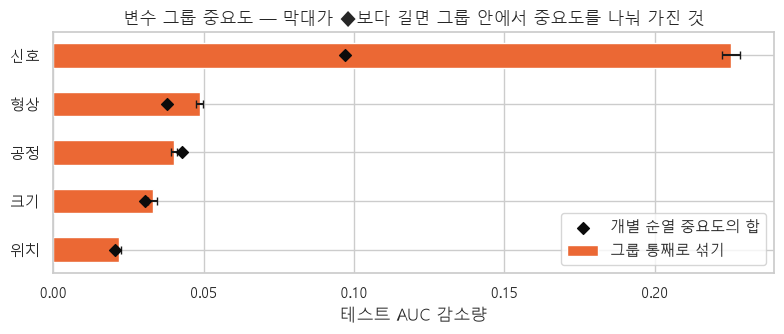

<a id="chapter-7-topic-186"></a>

### 알고리즘 상세 해설 · 변수 중요도 — 무엇을 섞었고 무엇을 측정했나?

MDI는 학습 나무의 불순도 감소, 순열 중요도는 고정된 모델에 입력을 섞었을 때 평가 점수 감소입니다.
순열 감소량이 작다고 변수가 언제나 불필요한 것은 아닙니다. 상관된 다른 변수가 정보를 대신 제공할 수 있습니다.
그룹 순열은 묶음 내부 관계를 유지하지만 다른 그룹과의 관계는 깨뜨립니다.

반복 순열의 표준편차는 섞는 순서에 따른 변동이며 데이터 표본 불확실성 전체를 포함하지 않습니다.
중요도 합이 성능을 구성하는 가산적 분해라고 보장하지 않으므로 “상위 5개가 성능의 80%를 설명”한다고 말하지 않습니다.
테스트 중요도는 고정 모델에 대한 사후 설명입니다. 이를 보고 변수를 선택·재학습하면 같은 테스트가 더는 독립 평가가 아닙니다.


,평균,표준편차
Step_desc,0.0429,0.0013
MDAT_GL,0.0422,0.0016
MDAT_OFFSET,0.0342,0.0011
SPOTLIKENESS,0.0233,0.0009
DEFECT_AREA,0.0200,0.0003
RADIUS,0.0197,0.0002
ACTIVERATIO,0.0087,0.0003
MDAT_NOISE,0.0066,0.0004


음의 순열 중요도 변수 수: 0
회귀 중요도는 뒤에서 로그 R² 감소를 사용합니다. 분류 AUC 감소와 직접 크기를 비교하지 않습니다.


**실행 결과와 그래프 읽기**

음수는 섞은 뒤 점수가 높아진 결과이며 샘플·반복 변동이나 모델 의존성과 관련될 수 있습니다. 자동 삭제 근거로 사용하지 않습니다.


> **이번 실행 결과 해석**
> 그룹을 함께 섞을 때의 감소량과 개별 감소량의 합은 같을 필요가 없습니다. 상관·상호작용·비현실적 조합의 영향을 함께 고려합니다.


**실습 프롬프트 P36**

> **[맥락]** best_clf, Xc_te, perm_clf(순열 중요도, 내림차순 정렬 가능)가 있어.
>
> **[작업]** 순열 중요도 상위 3개 수치형 변수의 부분 의존도(PDP)를 그려줘.
> - 범주형(Step_desc, POLARITY)은 제외하고 상위 3개 선택.
> - PartialDependenceDisplay.from_estimator(best_clf, Xc_te 중 무작위 3000행(random_state 고정), features,
>
>   kind='both'(평균 PDP + 개별 ICE), subsample=80, random_state=RANDOM_STATE, grid_resolution=40,
>
>   percentiles=(0.02, 0.98))
> - 평균선은 주황 굵게, ICE 선은 회색 얇게. y축 = 'REAL일 확률'.
>
> **[출력]** 1×3 그래프 + 변수별로 '값이 커질수록 REAL 확률이 ...' 해석.


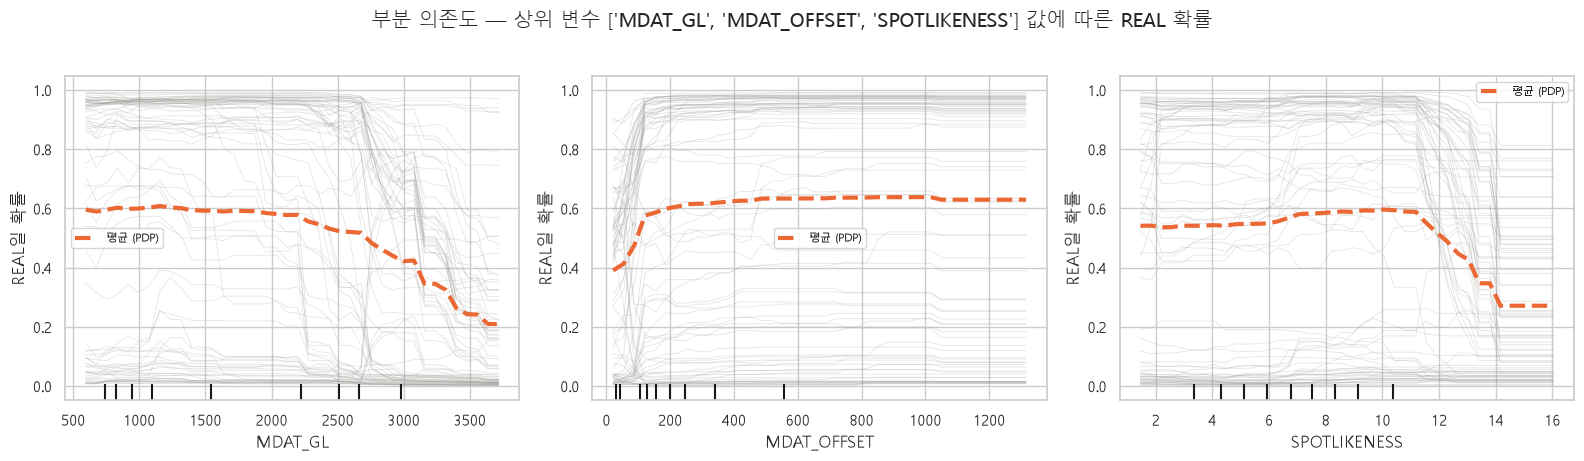

> **이번 실행 결과 해석**
> PDP·ICE의 곡선 방향과 표본별 차이를 읽습니다. 센서값 조작의 인과 효과로 해석하지 않습니다.


**실습 프롬프트 — 변수 선택까지 포함한 교차검증**

> 각 GroupKFold 학습 부분에서 RF 중요도를 새로 계산하고 상위 k개 변수를 선택한 뒤 같은 폴드의 검증 자료에 HGB AUC를 구해줘.
>
> 전체 학습 자료로 만든 순위를 CV 전체에 재사용하지 마. 이 탐색으로 테스트를 본 최종 모델을 바꾸지 마.


,mean,std
k,,
1,0.7588,0.0141
3,0.9139,0.0152
8,0.9345,0.0128
19,0.9483,0.0108


,폴드,k,AUC,선택변수
0,1,1,0.7747,MDAT_GL
1,1,3,0.9279,"MDAT_GL, MDAT_OFFSET, SPOTLIKENESS"
2,1,8,0.9465,"MDAT_GL, MDAT_OFFSET, SPOTLIKENESS, DEFECT_ARE..."
3,1,19,0.9591,"MDAT_GL, MDAT_OFFSET, SPOTLIKENESS, DEFECT_ARE..."
4,2,1,0.7537,MDAT_OFFSET
5,2,3,0.9160,"MDAT_OFFSET, MDAT_GL, SPOTLIKENESS"
6,2,8,0.9362,"MDAT_OFFSET, MDAT_GL, SPOTLIKENESS, RELATIVEMA..."
7,2,19,0.9484,"MDAT_OFFSET, MDAT_GL, SPOTLIKENESS, RELATIVEMA..."
8,3,1,0.7479,MDAT_GL
9,3,3,0.8977,"MDAT_GL, MDAT_OFFSET, SPOTLIKENESS"


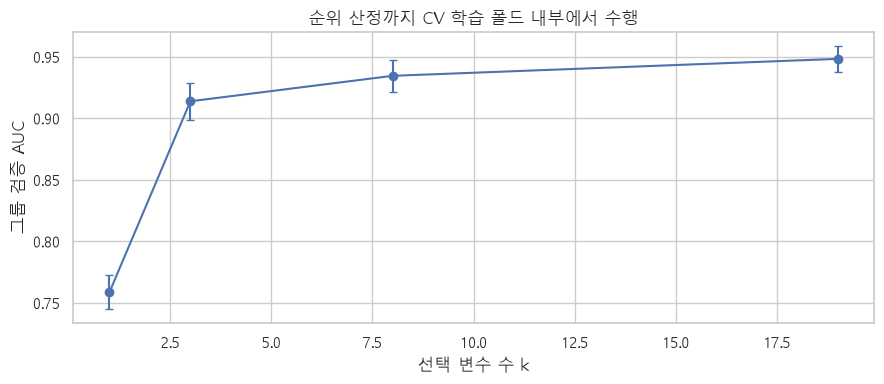

이 실험으로 최종 모델을 변경하지 않습니다. k를 최종 선택하면 새 독립 평가가 필요합니다.


> **이번 실행 결과 해석**
> 상위 변수 선택은 각 CV 학습 폴드 내부에서 수행했습니다. 폴드마다 선택 변수가 다를 수 있습니다. AUC의 99%를 성능 보존율로 해석하지 않고 실제 점수 차이를 보고합니다.


<a id="chapter-7-topic-196"></a>

### 7-2. 회귀 모델의 변수 중요도

같은 방법을 크기 추정 모델에 적용합니다. **분류와 회귀에서 중요한 변수가 같은지** 비교해 보세요.


**실습 프롬프트 P38**

> **[맥락]** best_reg(튜닝된 HGB 회귀 Pipeline), Xr_te, yr_te, final_reg['선형 회귀'], to_raw가 있어.
>
> **[작업]**
> 1. permutation_importance(best_reg, Xr_te, yr_te, scoring='r2', n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
>
>    → perm_reg(평균, 표준편차).
> 2. 선형 회귀 표준화 계수 coef_reg (원-핫 열 단위)도 구해줘.
> 3. 1×2 그래프: 왼쪽 순열 중요도 가로 막대(상위 3개 C_REAL, 나머지 C_GRAY, 오차막대),
>
>    오른쪽 선형 회귀 계수 상위 12개(양수=주황 '크게 예측', 음수=파랑 '작게 예측').


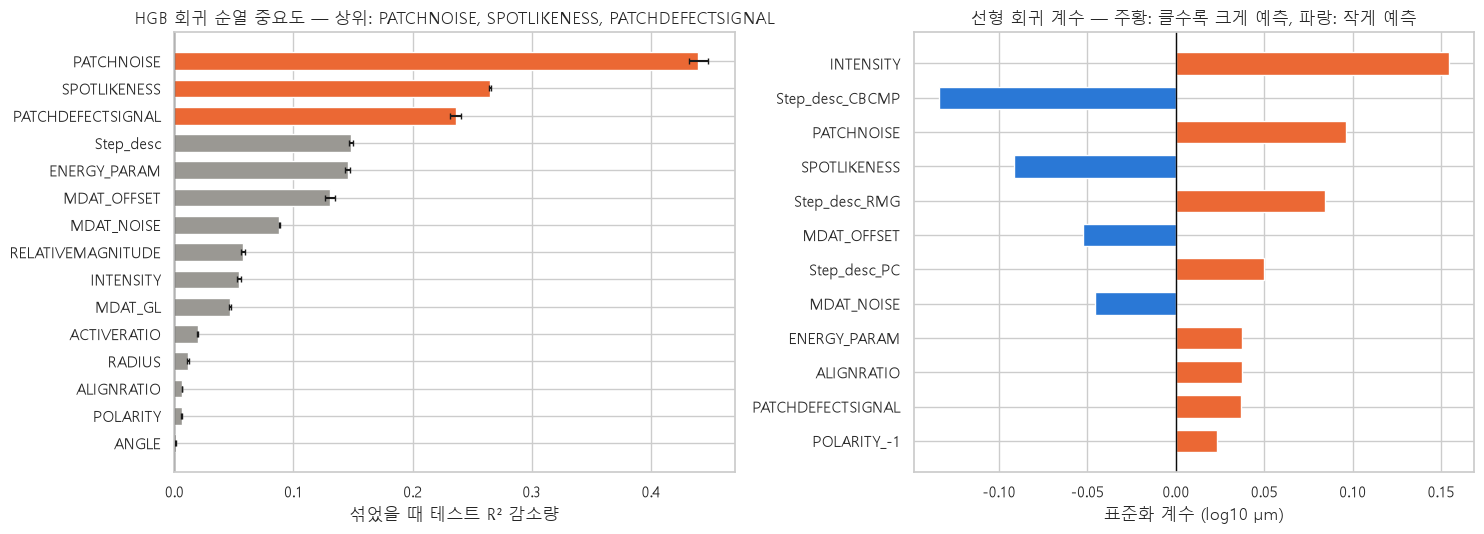

**실습 프롬프트 P39**

> **[맥락]** best_reg, Xr_te, perm_reg가 있어.
>
> **[작업]** 회귀 순열 중요도 상위 2개 수치형 변수의 PDP를 그려줘 (분류 PDP와 같은 형식).
> - 3000행 표본, kind='both', subsample=80, percentiles=(0.02, 0.98), grid_resolution=40
> - y축은 '예측 log10 SIZE_D'이고, 오른쪽 보조 눈금 대신 제목에 µm 환산 범위(10**최소~10**최대)를 적어줘.


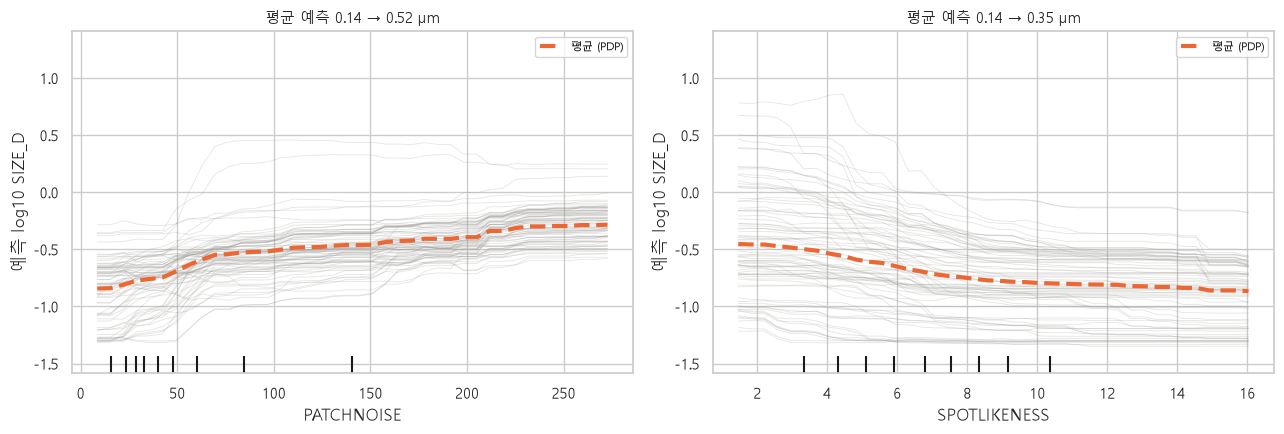

<a id="chapter-7-topic-201"></a>

### 알고리즘 상세 해설 · PDP·ICE — 입력을 바꾸어 모델의 반응 관찰하기

PDP는 다른 입력을 표본 그대로 둔 채 한 입력을 같은 값으로 바꾸고 예측을 평균낸 곡선입니다.
ICE는 같은 조작을 개별 표본별로 그립니다. 평균에 가려진 서로 다른 반응을 볼 수 있습니다.
관측되지 않은 입력 조합을 만들 수 있어 입력 간 상관이 강하면 해석에 특히 주의합니다.
그래프는 “이 센서값을 물리적으로 바꾸면 결함이 변한다”는 개입 효과가 아닙니다.

회귀 그림은 로그 예측을 평균한 후 역변환한 값입니다. 원단위 예측의 산술평균과 다릅니다.
2~98백분위 범위만 표시하므로 극단값 구간의 반응은 그림에서 확인할 수 없습니다.


로그 예측 평균의 역변환: 0.16788639731372254
원단위 예측의 평균: 0.32223308421040364
두 값은 평균과 비선형 역변환의 순서가 달라 일반적으로 다릅니다.


**실행 결과와 그래프 읽기**

진한 PDP 선은 평균 반응입니다. 얇은 ICE 선이 다양하면 표본마다 다른 반응이 있음을 시사합니다. 모든 곡선이 같아 보여도 인과관계가 증명되는 것은 아닙니다.


> **이번 실행 결과 해석**
> 회귀 PDP는 로그 예측의 평균 반응입니다. 역변환한 값은 원단위 산술평균과 다릅니다.


**실습 프롬프트 P40**

> **[맥락]** perm_clf(분류 순열 중요도), perm_reg(회귀 순열 중요도), group_of(변수→그룹 딕셔너리)가 있어.
>
> **[작업]** 두 과제의 변수 중요도를 한 표로 요약해줘.
> - 행: 모든 변수, 열: 그룹, 분류 순위, 분류 중요도(AUC 감소), 회귀 순위, 회귀 중요도(R² 감소)
> - 회귀에서 쓰지 않은 변수(크기 변수)는 '—'로.
> - 분류 순위 기준 정렬.
>
> **[출력]** 표 + 두 과제의 공통 핵심 변수와 차이를 해석.


,그룹,분류 순위,분류 중요도,회귀 순위,회귀 중요도
Step_desc,공정,1,0.0429,4,0.1482
MDAT_GL,신호,2,0.0422,10,0.0470
MDAT_OFFSET,신호,3,0.0342,6,0.1306
SPOTLIKENESS,형상,4,0.0233,2,0.2648
DEFECT_AREA,크기,5,0.0200,—,—
RADIUS,위치,6,0.0197,12,0.0114
ACTIVERATIO,형상,7,0.0087,11,0.0197
MDAT_NOISE,신호,8,0.0066,7,0.0883
SIZE_D,크기,9,0.0057,—,—
INTENSITY,신호,10,0.0044,9,0.0541


> **이번 실행 결과 해석**
> 분류 중요도는 AUC 감소, 회귀 중요도는 로그 R² 감소입니다. 두 과제의 순위를 비교할 수 있지만 수치 크기를 직접 비교하지 않습니다.


---

<a id="chapter-8"></a>

## 8장. 모델 저장 · 종합 리포트 · 연습문제

> **이 장의 목표**
> - 학습한 모델을 저장하고 새 데이터에 적용한다.
> - 분석 결과를 비전공자도 이해할 수 있게 요약한다.
> - 스스로 프롬프트를 작성해 모델링을 반복한다.

[전체 목차](#contents) · [이전 장](#chapter-7) · [다음 장](#review)

**이 장의 개념과 실습**

- [8-1. 모델 저장과 재사용 검산](#chapter-8-topic-209)
- [종합 리포트 — 이번 실행 결과 정리](#chapter-8-topic-215)
- [8-2. 개념 정리 체크리스트](#chapter-8-topic-217)
- [8-3. 연습문제 — 직접 프롬프트를 써서 풀어보세요](#chapter-8-topic-218)

**알고리즘 상세 해설 바로가기**

- [저장한 모델을 다시 사용할 때 확인할 것](#chapter-8-topic-212)


<a id="chapter-8-topic-209"></a>

### 8-1. 모델 저장과 재사용 검산


**실습 프롬프트 P41**

> **[맥락]** best_clf(분류 Pipeline), best_reg(회귀 Pipeline), THR, FEAT_CLF, FEAT_REG, Xc_te, Xr_te가 있어.
>
> **[작업]**
> 1. joblib으로 두 모델과 임계값·특성 목록을 하나의 딕셔너리로 묶어 'wafer_models.joblib'에 저장.
> 2. 다시 불러와서 테스트 데이터 앞 8행에 적용해 결과 표를 만들어줘:
>
>    REAL 확률, 판정(THR 기준 'REAL(리뷰)'/'FALSE(생략)'), 실제 IS_DEFECT, 예측 크기(µm), 실제 크기(µm).
>
> **[조건]** Pipeline 안에 전처리가 들어 있으므로 원본 열 그대로 넣으면 된다는 점을 주석으로 설명해줘.


저장 완료 : wafer_models_algorithm_expanded.joblib


,REAL 확률,판정,실제,예측 크기(µm),실제 크기(µm)
0,0.4650,REAL(리뷰),REAL,0.3960,0.5460
1,0.0130,FALSE(생략),FALSE,0.1640,0.1980
2,0.0200,FALSE(생략),FALSE,0.0830,0.0490
3,0.8700,REAL(리뷰),REAL,0.4910,0.6460
4,0.0090,FALSE(생략),FALSE,0.0670,0.0990
5,0.8400,REAL(리뷰),FALSE,0.2700,0.2480
6,0.0560,FALSE(생략),FALSE,0.2020,0.4470
7,0.8030,REAL(리뷰),REAL,0.2330,0.1980


<a id="chapter-8-topic-212"></a>

### 알고리즘 상세 해설 · 저장한 모델을 다시 사용할 때 확인할 것

학습한 모델뿐 아니라 전처리·입력 열·타깃 변환·임계값을 함께 저장해야 같은 예측을 재현할 수 있습니다.
예측 시 새 자료로 스케일러를 다시 fit하지 않습니다. 학습 때 배운 변환을 transform으로 적용합니다.
데이터 타입·단위·범주가 바뀌면 코드가 실행되어도 다른 의미의 예측이 될 수 있습니다.
joblib은 신뢰할 수 있는 직접 만든 파일만 불러오며 라이브러리 버전 차이가 있으면 호환성을 확인합니다.


저장·재로딩 전후 분류 확률과 회귀 예측 일치
저장한 scikit-learn 버전: 1.9.1


**실행 결과와 그래프 읽기**

저장·재로딩의 일치는 전달 과정에서 예측이 바뀌지 않았다는 검산입니다. 운영 품질이나 미래 데이터 성능을 보장하는 검증은 아닙니다.


<a id="chapter-8-topic-215"></a>

### 종합 리포트 — 이번 실행 결과 정리


## 이번 실행의 최종 보고서

,AUC,AP,정확도,정밀도,재현율(REAL),특이도(FALSE),F1
그래디언트부스팅(튜닝),0.9549,0.9557,0.9008,0.8783,0.9524,0.8371,0.9138
랜덤포레스트,0.9502,0.9474,0.9008,0.8765,0.9550,0.8339,0.9141
로지스틱 회귀,0.8393,0.8297,0.7646,0.7432,0.8768,0.6261,0.8045
Dummy,0.5000,0.5524,0.5524,0.5524,1.0000,0.0000,0.7117


,R²(로그),MAE(µm),RMSE(µm),MdAPE(%)
그래디언트부스팅(튜닝),0.8140,0.1250,0.8857,17.4887
랜덤포레스트,0.8127,0.1243,0.9246,17.0736
선형 회귀,0.4806,0.3023,3.0721,39.4676
Dummy,-0.0030,0.2530,1.1866,54.7795


분류 HGB의 테스트 AUC는 **0.9549**, 선택 임계값 **0.21**에서 재현율 **98.25%**, 리뷰 생략 건수 비율 **35.28%**, 놓친 REAL **115건**입니다.

회귀 HGB의 원단위 MAE는 **0.1250 µm**, 로그 R²는 **0.8140**입니다.

자료 전체: 63908 학습 로트: 365 테스트 로트: 92
이는 현재 보유 데이터의 로트 분할 평가이며 미래 기간·새 설비 성능 보장이 아닙니다.


<a id="chapter-8-topic-217"></a>

### 8-2. 개념 정리 체크리스트

| 개념 | 한 줄 정의 | 이 노트북 위치 |
|---|---|---|
| 데이터 누수 | 예측 시점에 모르는 정보가 학습에 섞임 | 2-2 (Class, 크기 변수), 3-1 (그룹), 5-4 (임계값) |
| 그룹 분할 | 같은 로트를 학습/테스트에 나누지 않음 | 3장 |
| Pipeline | 전처리 + 모델을 한 덩어리로, 교차검증 시 전처리 누수 방지 | 3-2 |
| 교차검증 | 학습 데이터를 k겹으로 돌려가며 검증 | 5장, 6장 |
| 기준 모델 | 아무것도 배우지 않은 모델 — 최소 비교 대상 | 4장, 5장, 6장 |
| ROC-AUC | 임계값 무관한 순위 능력 | 4-1, 5장 |
| 재현율 / 특이도 | 진성 놓치지 않기 / 가성 걸러내기 | 5-4 |
| MAE / RMSE / R² / MdAPE | 절대 / 큰 오차 강조 / 설명력 / 상대 오차 | 4-2, 6장 |
| 검증 곡선 · 학습 곡선 | 복잡도·데이터 양에 따른 과적합 진단 | 5-1 |
| 하이퍼파라미터 튜닝 | 교차검증으로 설정값 선택 | 5-2, 6장 |
| 순열 중요도 · PDP | 모델 무관 해석 — 얼마나 / 어느 방향으로 | 7장 |


<a id="chapter-8-topic-218"></a>

### 8-3. 연습문제 — 직접 프롬프트를 써서 풀어보세요

| # | 주제 | 과제 |
|:---:|---|---|
| 1 | 지표 | 임계값을 재현율 99%로 바꿔 THR을 다시 구하고, 테스트에서 리뷰 절감률이 얼마나 줄어드는지 비교 |
| 2 | 모델 | 공정이 CBCMP인 데이터만으로 분류 모델을 학습·평가하고, 전체 모델의 CBCMP 성능과 비교 |
| 3 | 누수 | `Class`를 특성에 넣은 모델의 교차검증 AUC를 구하고, 왜 쓸 수 없는지 설명 |
| 4 | 회귀 | `RADIUS`, `ANGLE`(위치)를 빼고 회귀 모델을 다시 학습해 R² 변화를 확인 |
| 5 | 중요도 | 회귀 모델에 그룹 순열 중요도(`group_perm`을 R² 버전으로 수정)를 적용 |
| 6 | 튜닝 | 랜덤포레스트 분류기의 `n_estimators`, `max_depth`, `min_samples_leaf`를 RandomizedSearchCV로 튜닝해 HGB와 비교 |


**연습문제 1 — 재현율 99% 임계값 : 나의 프롬프트**
```text
(여기에 프롬프트를 작성하세요)
[맥락]
[작업]
[검증 방법]
[조건]
[출력]
```


**연습문제 2 — CBCMP 전용 모델 : 나의 프롬프트**
```text
(여기에 프롬프트를 작성하세요)
[맥락]
[작업]
[검증 방법]
[조건]
[출력]
```


**연습문제 3 — Class 누수 실험 : 나의 프롬프트**
```text
(여기에 프롬프트를 작성하세요)
[맥락]
[작업]
[검증 방법]
[조건]
[출력]
```


**연습문제 4 — 위치 변수 제거 회귀 : 나의 프롬프트**
```text
(여기에 프롬프트를 작성하세요)
[맥락]
[작업]
[검증 방법]
[조건]
[출력]
```


**연습문제 5 — 회귀 그룹 중요도 : 나의 프롬프트**
```text
(여기에 프롬프트를 작성하세요)
[맥락]
[작업]
[검증 방법]
[조건]
[출력]
```


**연습문제 6 — 랜덤포레스트 튜닝 : 나의 프롬프트**
```text
(여기에 프롬프트를 작성하세요)
[맥락]
[작업]
[검증 방법]
[조건]
[출력]
```


---
<details>
<summary><b>연습문제 예시 프롬프트 & 답안 (클릭하여 펼치기)</b></summary>

**1. 예시 프롬프트** : "학습 OOF 확률 `oof`와 `yc_tr`로 재현율 0.99 이상인 가장 큰 임계값 THR99를 구하고, 테스트 확률 `p_best`에 THR과 THR99를 적용해 리뷰 생략 비율과 놓친 진성결함 수를 표로 비교해줘. 테스트로 임계값을 정하지 마."
```python
THR99 = thr_tbl.loc[thr_tbl["재현율"] >= 0.99, "임계값"].max()
pd.DataFrame({t: {"리뷰 생략 비율": (p_best < t).mean(),
                  "놓친 진성결함": ((p_best < t) & (yc_te.values == 1)).sum()} for t in [THR, THR99]})
```

**2.**
```python
m_tr, m_te = Xc_tr["Step_desc"] == "CBCMP", Xc_te["Step_desc"] == "CBCMP"
cb = clf_pipe(HistGradientBoostingClassifier(random_state=RANDOM_STATE)).fit(Xc_tr[m_tr], yc_tr[m_tr])
print("CBCMP 전용:", roc_auc_score(yc_te[m_te], cb.predict_proba(Xc_te[m_te])[:, 1]))
print("전체 모델 :", roc_auc_score(yc_te[m_te], p_best[m_te.values]))
```

**3.**
```python
CAT_COLS = ["Step_desc", "POLARITY", "Class"]        # Class를 범주형으로 추가 (실험용)
leaky = clf_pipe(HistGradientBoostingClassifier(random_state=RANDOM_STATE), features=FEAT_CLF + ["Class"])
print(cross_validate(leaky, tr[FEAT_CLF + ["Class"]], yc_tr, cv=gkf, groups=g_tr, scoring="roc_auc")["test_score"].mean())
CAT_COLS = ["Step_desc", "POLARITY"]                 # 원래대로 되돌리기
```

**4.**
```python
f4 = [c for c in FEAT_REG if c not in POS_COLS]
print(cross_validate(reg_pipe(HistGradientBoostingRegressor(random_state=RANDOM_STATE), features=f4),
                     Xr_tr[f4], yr_tr, cv=gkf, groups=g_tr, scoring="r2")["test_score"].mean())
```

**5.** `group_perm` 안의 `roc_auc_score(y, model.predict_proba(X)[:, 1])`를 `r2_score(y, model.predict(X))`로 바꾸고, 그룹에서 "크기"를 뺀 뒤 `best_reg`, `Xr_te`, `yr_te`로 실행

**6.**
```python
rf_search = RandomizedSearchCV(clf_pipe(RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE)),
    {"model__n_estimators": [100, 200, 400], "model__max_depth": [None, 10, 20],
     "model__min_samples_leaf": [1, 2, 5, 10]}, n_iter=8, cv=gkf, scoring="roc_auc", random_state=RANDOM_STATE)
rf_search.fit(Xc_tr, yc_tr, groups=g_tr); print(rf_search.best_params_, rf_search.best_score_)
```
</details>

---


#### 수고하셨습니다!

**다음 단계** : 모델 모니터링(새 로트에서 성능이 유지되는지) → 확률 보정(Calibration) → 비용 기반 임계값 최적화


---

<a id="review"></a>

## 알고리즘 복습·실습 문제

| 문제 | 답에 반드시 포함할 것 |
|---|---|
| 1. 선형 회귀와 로지스틱 회귀에서 예측값·손실은 어떻게 다른가? | 수치 vs 확률, 제곱오차 vs 로그손실 |
| 2. 릿지 alpha와 로지스틱 C를 크게 하면 정규화는 각각 어떻게 되는가? | alpha 증가=강화, C 증가=약화 |
| 3. 지니가 0인 리프가 많은 나무가 항상 좋은가? | 학습 순도와 일반화 구분 |
| 4. RF의 나무 수와 HGB 반복 수는 왜 같은 의미가 아닌가? | 독립적 평균 vs 순차적 보정 |
| 5. 로트가 겹치지 않으면 모든 누수가 사라지는가? | 입력 생성 시점·전처리·변수 선택 누수 |
| 6. AUC가 좋은 모델은 임계값 0.5에서도 재현율이 높은가? | 순위와 판정 분리 |
| 7. 로그 R²와 원단위 MAE의 최선 모델이 다르면 무엇을 선택하는가? | 현장 오차 비용·평가 기준 |
| 8. 순열 중요도가 낮으면 변수를 바로 버려도 되는가? | 상관 변수 대체·재학습 검증 |

[전체 목차](#contents) · [이전 장](#chapter-8)

**이 장의 개념과 실습**

- [직접 바꿔 보는 실행 과제](#review-topic-234)
- [실제 적용을 설명하는 보고서 틀](#review-topic-237)
- [참고: scikit-learn 공식 문서](#review-topic-238)


<a id="review-topic-234"></a>

### 직접 바꿔 보는 실행 과제

아래는 **학습 영역의 별도 그룹 검증 폴드**만 사용하는 실습입니다. 이미 테스트 결과를 본 뒤 모델을 개선하는 훈련이므로
그 결과를 기존 테스트에서의 새로운 독립 최종 점수로 보고하지 않습니다.
로지스틱 C를 바꿔 계수 길이·AUC·수렴 여부를 확인하고, 다음으로 트리 `min_samples_leaf`를 바꾸어 보세요.


,C,계수 L2 길이,학습 AUC,검증 AUC,솔버 반복 수
0,0.0100,2.1026,0.8338,0.8549,25
1,1.0000,4.3734,0.8366,0.8572,46
2,100.0000,4.7076,0.8367,0.8573,45


**해설**: C가 커지면 정규화가 약해져 계수 길이가 커질 수 있습니다. 검증 AUC도 항상 커지는 것은 아닙니다.
수렴 경고가 있다면 점수만 읽지 말고 스케일·입력 분포·반복 횟수를 먼저 확인합니다. 한 폴드 실습은 정식 CV 비교와 다릅니다.


<a id="review-topic-237"></a>

### 실제 적용을 설명하는 보고서 틀

1. 예측 시점과 사용 가능한 입력은 무엇인가?
2. 알고리즘은 어떤 형태의 규칙을 배우고 어떤 손실을 줄이는가?
3. 로트 분할과 전처리 학습은 어떻게 이루어졌는가?
4. 설정·임계값은 어떤 학습/검증 데이터로 결정했는가?
5. 테스트 n·로트 수·지표·FN·공정별 약점은 무엇인가?
6. 테스트 결과를 본 뒤 변경한 것이 있다면 새 최종 검증은 어떻게 확보할 것인가?


<a id="review-topic-238"></a>

### 참고: scikit-learn 공식 문서

설명은 원리 학습용으로 구성했고, API·구현상의 세부 사항은 아래 공식 문서와 설치 버전으로 확인했습니다.

- [선형 모델·릿지·로지스틱 회귀](https://scikit-learn.org/stable/modules/linear_model.html)
- [의사결정나무](https://scikit-learn.org/stable/modules/tree.html)
- [랜덤포레스트·그래디언트 부스팅·HGB](https://scikit-learn.org/stable/modules/ensemble.html)
- [그룹 분할과 교차검증](https://scikit-learn.org/stable/modules/cross_validation.html)

웹 문서의 버전과 로컬 설치 버전이 다를 수 있으므로 첫 셀에 출력된 버전과 실제 실행 결과를 기준으로 재현합니다.


검산 완료: 로트 분리·원본 유지·예측값·입력 역할·저장 모델 확인
